In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
products = pd.read_csv("products.csv", sep=";", encoding="utf-8-sig")
transactions = pd.read_csv("transactions.csv", sep= ";", encoding="utf-8-sig")
customers = pd.read_csv("customers.csv", sep=";", encoding="utf-8-sig")

C:\Users\Vecto\AppData\Local\Temp\ipykernel_22960\1493390915.py:2: DtypeWarning: Columns (0,1,2,3) have mixed types. Specify dtype option on import or set low_memory=False.
  transactions = pd.read_csv("transactions.csv", sep= ";", encoding="utf-8-sig")


In [3]:
products.head()

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0


In [4]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id_prod  3286 non-null   object 
 1   price    3286 non-null   float64
 2   categ    3286 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 77.1+ KB


In [5]:
customers.head()

,client_id,sex,birth
0,c_4410,f,1967
1,c_7839,f,1975
2,c_1699,f,1984
3,c_5961,f,1962
4,c_5320,m,1943


In [6]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8621 entries, 0 to 8620
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   client_id  8621 non-null   object
 1   sex        8621 non-null   object
 2   birth      8621 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 202.2+ KB


In [7]:
transactions.head()

,id_prod,date,session_id,client_id
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033


In [8]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_prod     687534 non-null  object
 1   date        687534 non-null  object
 2   session_id  687534 non-null  object
 3   client_id   687534 non-null  object
dtypes: object(4)
memory usage: 32.0+ MB


In [9]:
# supprimer les lignes vides de la table transactions et convertir les dates en format date
transactions = transactions.dropna()
transactions["date"] = pd.to_datetime(transactions["date"])

In [10]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
Index: 687534 entries, 0 to 687533
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   id_prod     687534 non-null  object        
 1   date        687534 non-null  datetime64[ns]
 2   session_id  687534 non-null  object        
 3   client_id   687534 non-null  object        
dtypes: datetime64[ns](1), object(3)
memory usage: 26.2+ MB


<div style="border: 2px solid magenta; padding: 10px;">
<span style="color: magenta; font-size: 24px; font-weight: bold"> Structurer les données
</span>
</div>


<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> Table customers </span>
</div>

In [11]:
# je crée une variable age calculé 2023 parce que les données s'arrêtent en 2023
customers["age"] = 2023 - customers["birth"]

In [12]:
customers.head()

,client_id,sex,birth,age
0,c_4410,f,1967,56
1,c_7839,f,1975,48
2,c_1699,f,1984,39
3,c_5961,f,1962,61
4,c_5320,m,1943,80


In [13]:
# création de tranche d'age avec interval de 10
bins_age = [17, 21, 31, 41, 51, 61, 71, 81, float("inf")]

labels_age = [
    "19-20 ans",
    "21-30 ans",
    "31-40 ans",
    "41-50 ans",
    "51-60 ans",
    "61-70 ans",
    "71-80 ans",
    "81 ans et plus"
]

customers["tranche_age10"] = pd.cut(
    customers["age"],
    bins=bins_age,
    labels=labels_age,
    right=False,
    include_lowest=True
)

In [14]:
customers.head()

,client_id,sex,birth,age,tranche_age10
0,c_4410,f,1967,56,51-60 ans
1,c_7839,f,1975,48,41-50 ans
2,c_1699,f,1984,39,31-40 ans
3,c_5961,f,1962,61,61-70 ans
4,c_5320,m,1943,80,71-80 ans


In [15]:
bins_age_4 = [17, 31, 51, 71, float("inf")]

labels_age_4 = [
    "17-30 ans",
    "31-50 ans",
    "51-70 ans",
    "71 ans et plus"
]

customers["tranche_age20"] = pd.cut(
    customers["age"],
    bins=bins_age_4,
    labels=labels_age_4,
    right=False,
    include_lowest=True
)

In [16]:
customers["tranche_age20"].value_counts().sort_index()

tranche_age20
17-30 ans         2092
31-50 ans         3413
51-70 ans         2467
71 ans et plus     649
Name: count, dtype: int64

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> Création de la table des ventes </span>
</div>

In [17]:
# Je fusionne les 3 tables pour créer la table des vente
# d'abord, ajouter des informations sur le produit, prix et catégorie du livre vendu à chaque transactiion
ventes = transactions.merge(products, on="id_prod", how = "left")
ventes.head()

,id_prod,date,session_id,client_id,price,categ
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,11.99,0
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,19.37,0
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,4.50,0
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,6.55,0
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,16.49,0


In [18]:
# et ajouter les informations clients pour chaque session
ventes = ventes.merge(customers, on="client_id", how="left")
ventes.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,tranche_age10,tranche_age20
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,11.99,0,f,1967,56,51-60 ans,51-70 ans
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,19.37,0,m,1960,63,61-70 ans,51-70 ans
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,4.50,0,m,1988,35,31-40 ans,31-50 ans
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,6.55,0,f,1989,34,31-40 ans,31-50 ans
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,16.49,0,f,1956,67,61-70 ans,51-70 ans


In [19]:
# j'ajoute des variables year, month, day et week pour l'analyse temporelle
ventes["year"] = ventes["date"].dt.year
ventes["month"] = ventes["date"].dt.to_period("M")
ventes["week"] = ventes["date"].dt.to_period("W")
ventes["day"] = ventes["date"].dt.date

In [20]:
ventes.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,tranche_age10,tranche_age20,year,month,week,day
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,11.99,0,f,1967,56,51-60 ans,51-70 ans,2021,2021-03,2021-03-01/2021-03-07,2021-03-01
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,19.37,0,m,1960,63,61-70 ans,51-70 ans,2021,2021-03,2021-03-01/2021-03-07,2021-03-01
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,4.50,0,m,1988,35,31-40 ans,31-50 ans,2021,2021-03,2021-03-01/2021-03-07,2021-03-01
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,6.55,0,f,1989,34,31-40 ans,31-50 ans,2021,2021-03,2021-03-01/2021-03-07,2021-03-01
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,16.49,0,f,1956,67,61-70 ans,51-70 ans,2021,2021-03,2021-03-01/2021-03-07,2021-03-01


In [21]:
# ventes.to_excel("ventes.xlsx", index=False)

In [22]:
# j'ajoute l'age du client au moment de l'achat
# ventes["age_achat"] = ventes["year"] - ventes["birth"]

In [23]:
# ventes[["date", "year", "month", "day", "birth", "age"]].head()

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> Création de la table des clients_stats </span>
</div>

In [24]:
# construction d'une table clients_stats, à partir de la table des ventes
# une ligne par client - les clients qui n'ont jamais acheté sont exclus
clients_stats = ventes.groupby("client_id").agg(
    sex=("sex", "first"),
    birth=("birth", "first"),
    age=("age", "first"),
    tranche_age10=("tranche_age10", "first"),
    tranche_age20=("tranche_age20", "first"),
    montant_total=("price", "sum"),
    nombre_achats=("session_id", "nunique"),
    nombre_produits=("id_prod", "count")
).reset_index()

In [25]:
# ajouter une ligne de valeur moyen de panier en divisant le montant total par le nombre des paniers
clients_stats["panier_moyen"] = (
    clients_stats["montant_total"] / clients_stats["nombre_achats"]
).round(2)

In [26]:
clients_stats.head()

,client_id,sex,birth,age,tranche_age10,tranche_age20,montant_total,nombre_achats,nombre_produits,panier_moyen
0,c_1,m,1955,68,61-70 ans,51-70 ans,629.02,34,43,18.50
1,c_10,m,1956,67,61-70 ans,51-70 ans,1353.60,34,58,39.81
2,c_100,m,1992,31,31-40 ans,31-50 ans,254.85,5,8,50.97
3,c_1000,f,1966,57,51-60 ans,51-70 ans,2291.88,94,126,24.38
4,c_1001,m,1982,41,41-50 ans,31-50 ans,1823.85,47,103,38.81


In [27]:
clients_stats.shape

(8600, 10)

In [28]:
# je sais (je l'ai vu plus bas) que les 4 plus gros clients sont les B to B
# je vais donc créer une table pour les clients B to B
# créer une table pour les B to B
clients_b2b = (
    clients_stats
    .sort_values("montant_total", ascending=False)
    .head(4)["client_id"]
)

In [29]:
clients_b2b.head()

677     c_1609
4388    c_4958
6337    c_6714
2724    c_3454
Name: client_id, dtype: object

In [30]:
# créer une table pour les clients B to c en excluant les 4
# "copy" pour être sûr d'avoir une nouvelle table indépendante
clients_stats_b2c = clients_stats[
    ~clients_stats["client_id"].isin(clients_b2b)
].copy()

In [31]:
clients_stats_b2c.shape

(8596, 10)

In [32]:
# et une table à part pour les clients B to B
clients_stats_b2b = clients_stats[
    clients_stats["client_id"].isin(clients_b2b)
].copy()

In [33]:
clients_stats_b2b.head()

,client_id,sex,birth,age,tranche_age10,tranche_age20,montant_total,nombre_achats,nombre_produits,panier_moyen
677,c_1609,m,1980,43,41-50 ans,31-50 ans,326039.89,10997,25586,29.65
2724,c_3454,m,1969,54,51-60 ans,51-70 ans,114110.57,5571,6793,20.48
4388,c_4958,m,1999,24,21-30 ans,17-30 ans,290227.03,3851,5222,75.36
6337,c_6714,f,1968,55,51-60 ans,51-70 ans,153918.60,2620,9199,58.75


<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> tables des ventes en séparant BtoB et BtoC </span>
</div>

In [34]:
# table ventes avec les B to B seulement 

ventes_b2b = ventes[ventes["client_id"].isin(clients_b2b)].copy()
ventes_b2b.shape

(46800, 15)

In [35]:
# ventes_b2b.to_excel("ventes_b2b.xlsx", index=False)

In [36]:
# table ventes avec les B to C seulement 

ventes_b2c = ventes[~ventes["client_id"].isin(clients_b2b)].copy()
ventes_b2c.shape

(640734, 15)

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> tables des catégories </span>
</div>

In [37]:
produits_stats = (
    ventes.groupby("id_prod")
    .agg(
        quantite_totale=("id_prod", "size"),
        ca_total=("price", "sum"),
        price=("price" , "first"),
        categ=("categ" , "first")
    )
    .reset_index()
)

In [38]:
produits_stats.head()

,id_prod,quantite_totale,ca_total,price,categ
0,0_0,1242,4657.50,3.75,0
1,0_1,487,5352.13,10.99,0
2,0_10,22,394.90,17.95,0
3,0_100,3,61.80,20.60,0
4,0_1000,432,2954.88,6.84,0


In [39]:
tableau_categories = (
    produits_stats.groupby("categ", observed=False)
    .agg(
        nombre_produits=("id_prod", "nunique"),
        prix_moyen=("price", "mean"),
        quantite_moyenne=("quantite_totale", "mean"),
        quantite_totale=("quantite_totale", "sum"),
        ca_moyen=("ca_total", "mean"),
        ca_total=("ca_total", "sum")
    )
    .reset_index()
)

In [40]:
# tableau des catégories avec uniquement des produits deja vendu
# les titres jamais vendus sont exclus du catalogue
tableau_categories.head()

,categ,nombre_produits,prix_moyen,quantite_moyenne,quantite_totale,ca_moyen,ca_total
0,0,2292,11.714760,181.264834,415459,1928.329394,4419730.97
1,1,737,25.503623,319.663501,235592,6550.416703,4827657.11
2,2,236,107.636017,154.588983,36483,11780.826356,2780275.02


In [41]:
# tableau_categories.to_excel("tableau_categories.xlsx", index=False)

In [42]:
# tableau de comparaison des catégories avec couleurs (alternative Excel)
colonnes_comparaison = [ "nombre_produits", "prix_moyen", "quantite_moyenne", "quantite_totale", "ca_moyen", "ca_total"]

tableau_style = (
    tableau_categories.style
    .hide(axis="index")

    .format(
        {
            "categ": "{:.0f}",
            "nombre_produits": "{:,.0f}",
            "prix_moyen": "{:,.2f} €",
            "quantite_moyenne": "{:,.2f}",
            "quantite_totale": "{:,.0f}",
            "ca_moyen": "{:,.2f} €",
            "ca_total": "{:,.2f} €"
        },
        decimal=",",
        thousands=" "
    )

    # Intensité calculée indépendamment dans chaque colonne
    .background_gradient(
        cmap="Greens",
        subset=colonnes_comparaison,
        axis=0
    )

    .set_properties(**{ "text-align": "center"})

    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "8px"),
                ("border", "1px solid #777")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "7px"),
                ("border", "1px solid #aaa")
            ]
        }
    ])
)

display(tableau_style)

categ,nombre_produits,prix_moyen,quantite_moyenne,quantite_totale,ca_moyen,ca_total
0,2 292,"11,71 €","181,26",415 459,"1 928,33 €","4 419 730,97 €"
1,737,"25,50 €","319,66",235 592,"6 550,42 €","4 827 657,11 €"
2,236,"107,64 €","154,59",36 483,"11 780,83 €","2 780 275,02 €"


<div style="border: 2px solid magenta; padding: 10px;">
<span style="color: magenta; font-size: 24px; font-weight: bold"> Analyse des évolutions
</span>
</div>

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        1- Evolution globale de chiffre d'affaire
    </span>
</div>

In [43]:
# je calcul le chiffre d'affaire totale
ca_total = ventes ["price"].sum()
print(f"chiffre d'affaire totale: {ca_total:,.2f} €")

chiffre d'affaire totale: 12,027,663.10 €


In [44]:
# je crée une nouvelle table pour le graphique: chiffre d'affaire par jour
# je dois le redéfinir pour chaque graphique?
ca_jour = ventes.groupby("day")["price"].sum()

In [45]:
# ajout d'une liste de dates menuelles pour les labels de l'axe X- on prend le début de chaque mois
mois = pd.date_range(ca_jour.index.min(), ca_jour.index.max(), freq="MS")

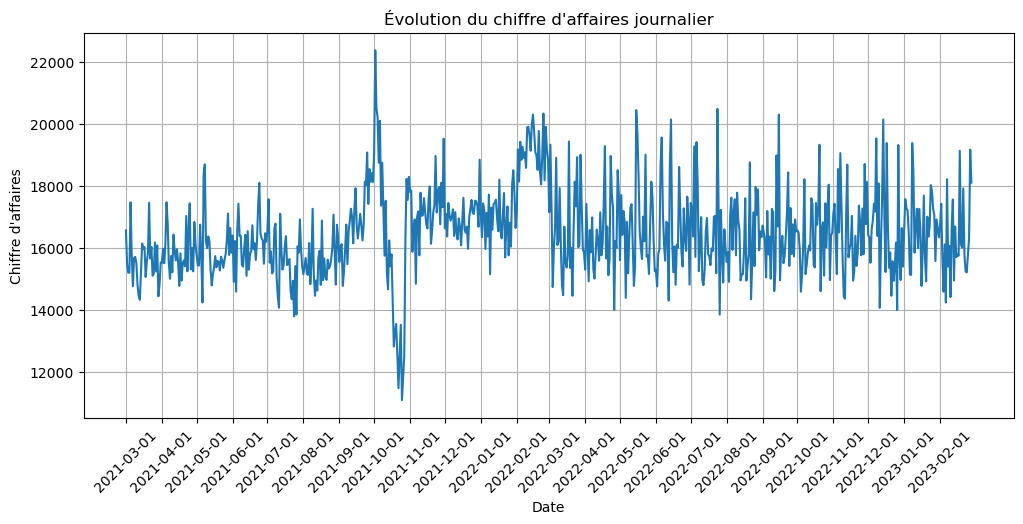

In [46]:
ca_jour = ventes.groupby("day")["price"].sum()
plt.figure(figsize=(12,5))
plt.plot(ca_jour.index, ca_jour.values)
plt.title("Évolution du chiffre d'affaires journalier")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.show()

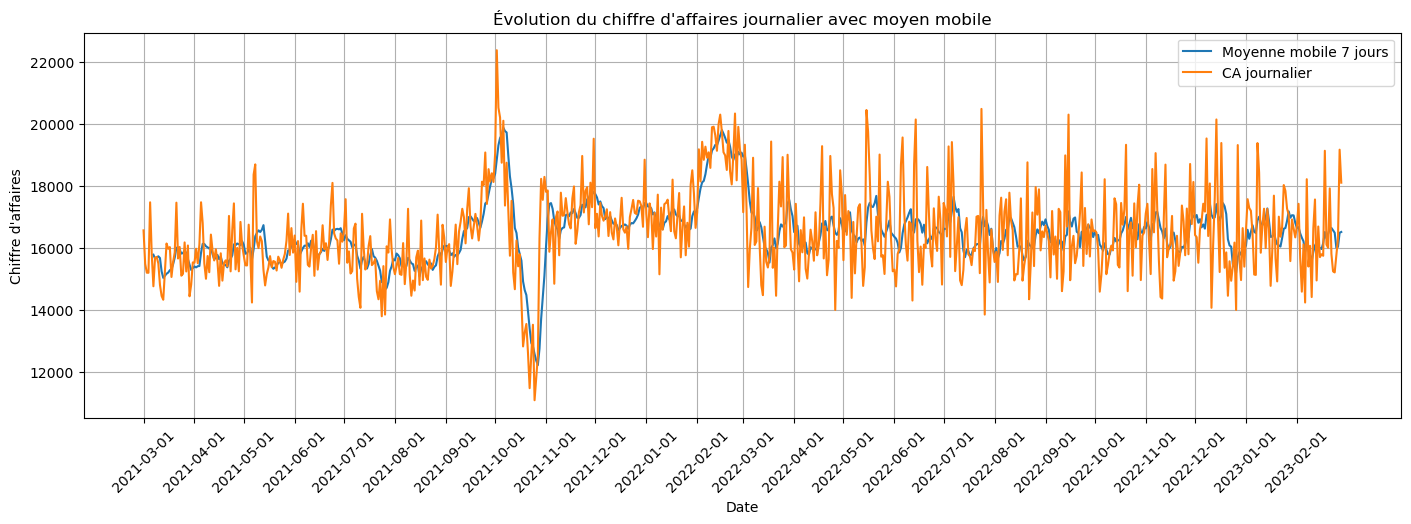

In [47]:
# je calcul la moyenne mobile sur 7 jours
# La moyenne mobile est calculée sur 7 jours afin de lisser les variations quotidiennes 
# et de faire apparaître une tendance hebdomadaire du chiffre d'affaires.
ca_jour_mobile = ca_jour.rolling(window=7).mean()
# ca_jour = ventes.groupby("day")["price"].sum()

plt.figure(figsize=(17,5))

plt.plot(ca_jour_mobile.index, ca_jour_mobile.values, label="Moyenne mobile 7 jours")
plt.plot(ca_jour.index, ca_jour.values, label="CA journalier")

plt.title("Évolution du chiffre d'affaires journalier avec moyen mobile")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
plt.show()

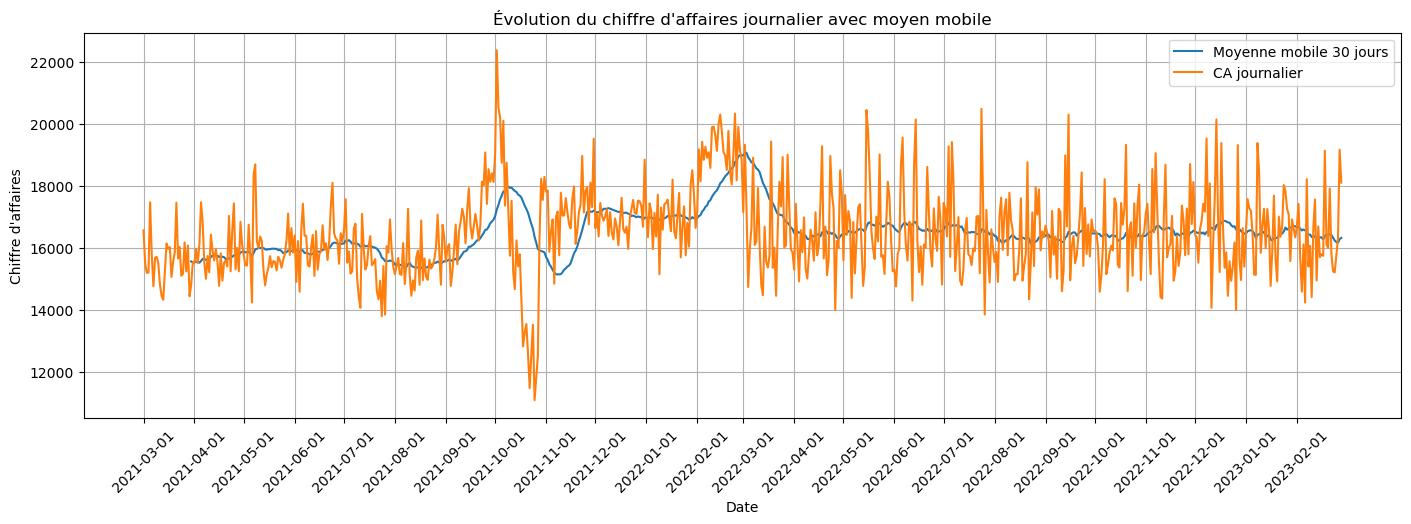

In [48]:
# je calcul la moyenne mobile sur 30 jours

ca_jour_mobile = ca_jour.rolling(window=30).mean()
ca_jour = ventes.groupby("day")["price"].sum()

plt.figure(figsize=(17,5))

plt.plot(ca_jour_mobile.index, ca_jour_mobile.values, label="Moyenne mobile 30 jours")
plt.plot(ca_jour.index, ca_jour.values, label="CA journalier")

plt.title("Évolution du chiffre d'affaires journalier avec moyen mobile")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
plt.show()

In [49]:
# evolution de chiffre d'affaire par semaine et par mois
#définir une table chiffre d'affaire par semaine 
# et une table de chiffre d'affaire par mois
ca_week = ventes.groupby("week")["price"].sum()
ca_month = ventes.groupby("month")["price"].sum()

In [50]:
ca_week.head()

week
2021-03-01/2021-03-07    110463.28
2021-03-08/2021-03-14    105693.24
2021-03-15/2021-03-21    112059.08
2021-03-22/2021-03-28    109441.07
2021-03-29/2021-04-04    107895.66
Freq: W-SUN, Name: price, dtype: float64

In [51]:
ca_month.head()

month
2021-03    482440.61
2021-04    476109.30
2021-05    492943.47
2021-06    484088.56
2021-07    482835.40
Freq: M, Name: price, dtype: float64

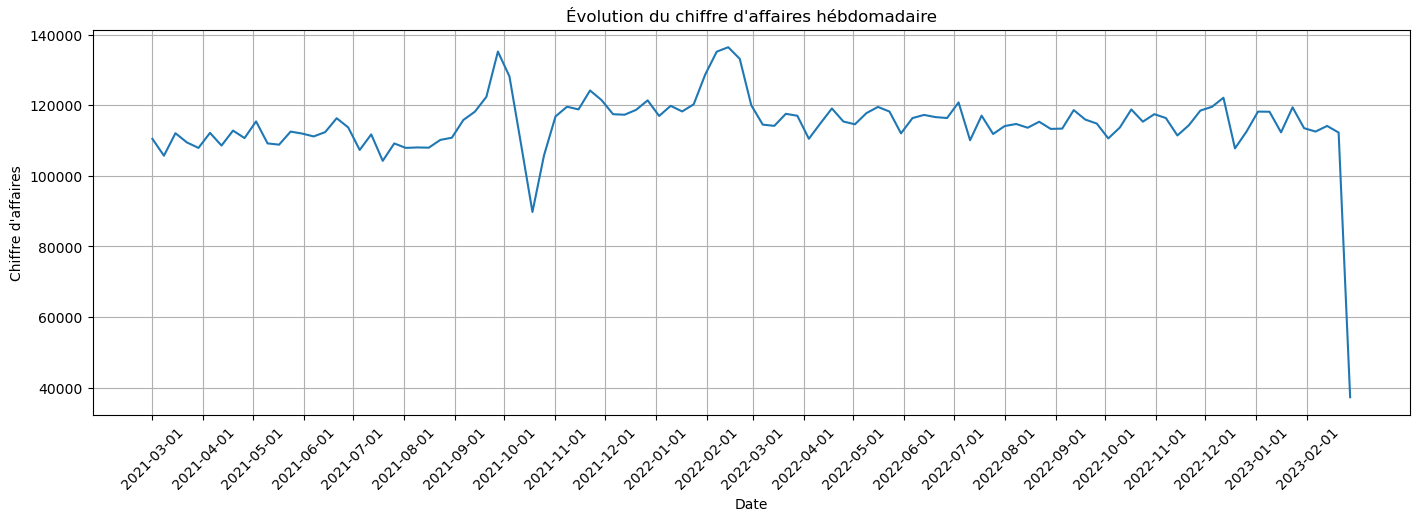

In [52]:
# évolution de chiffre d'affaire par semaine
# (devrait ressembler à moyens mobile de 7)
ca_week = ventes.groupby("week")["price"].sum()

plt.figure(figsize=(17,5))

# if faut dire que l'index semaine est une date, car il ne le reconnait pas autrement
plt.plot(ca_week.index.to_timestamp(), ca_week.values)

plt.title("Évolution du chiffre d'affaires hébdomadaire")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.show()

In [53]:
ca_week.tail()

week
2023-01-30/2023-02-05    113486.13
2023-02-06/2023-02-12    112528.15
2023-02-13/2023-02-19    114121.61
2023-02-20/2023-02-26    112245.15
2023-02-27/2023-03-05     37275.96
Freq: W-SUN, Name: price, dtype: float64

In [54]:
ca_jour.tail(10)

day
2023-02-19    16106.80
2023-02-20    16002.97
2023-02-21    17920.25
2023-02-22    15806.03
2023-02-23    15242.04
2023-02-24    15207.89
2023-02-25    15761.25
2023-02-26    16304.72
2023-02-27    19170.81
2023-02-28    18105.15
Name: price, dtype: float64

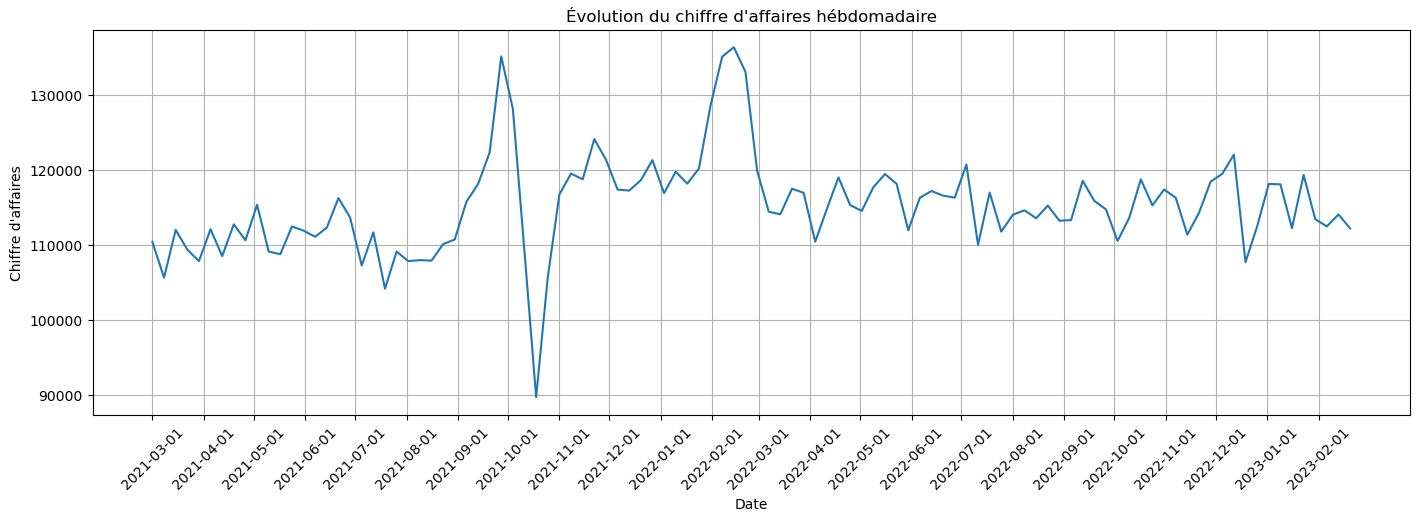

In [55]:
# la dernière semaine n'a que deux jours et fausse le graphique. retirer la semaine finale incomplète:
# évolution de chiffre d'affaire par semaine
# (devrait ressembler à moyens mobile de 7)
ca_week = ventes.groupby("week")["price"].sum()
ca_week_complet = ca_week.iloc[:-1]

plt.figure(figsize=(17,5))

# if faut dire que l'index semaine est une date, car il ne le reconnait pas autrement
plt.plot(ca_week_complet.index.to_timestamp(), ca_week_complet.values)

plt.title("Évolution du chiffre d'affaires hébdomadaire")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.show()


In [56]:
# chiffre d'affaire hebdomadaire et moyen mobile de 7 jours sur le même graph. 

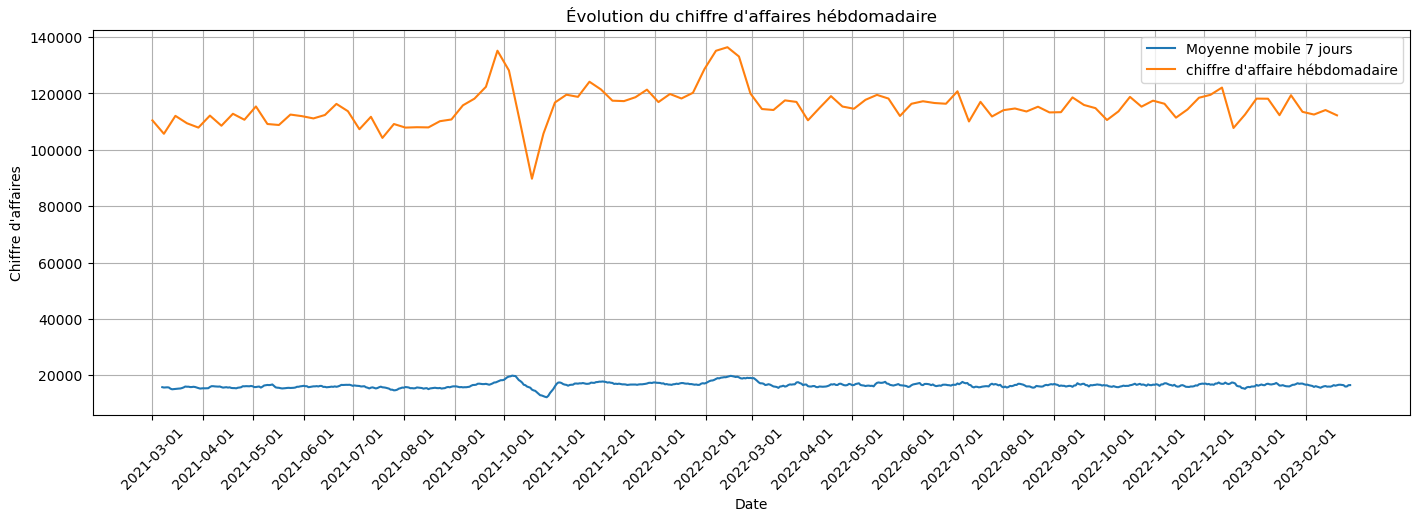

In [57]:

ca_jour_mobile = ca_jour.rolling(window=7).mean()
plt.figure(figsize=(17,5))

plt.plot(ca_jour_mobile.index, ca_jour_mobile.values, label="Moyenne mobile 7 jours")
plt.plot(ca_week_complet.index.to_timestamp(), ca_week_complet.values, label="chiffre d'affaire hébdomadaire")

plt.title("Évolution du chiffre d'affaires hébdomadaire")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
plt.show()

In [58]:
ca_month = ventes.groupby("month")["price"].sum()

In [59]:
ca_month.tail()

month
2022-10    507917.77
2022-11    496664.94
2022-12    510219.50
2023-01    517540.55
2023-02    456679.76
Freq: M, Name: price, dtype: float64

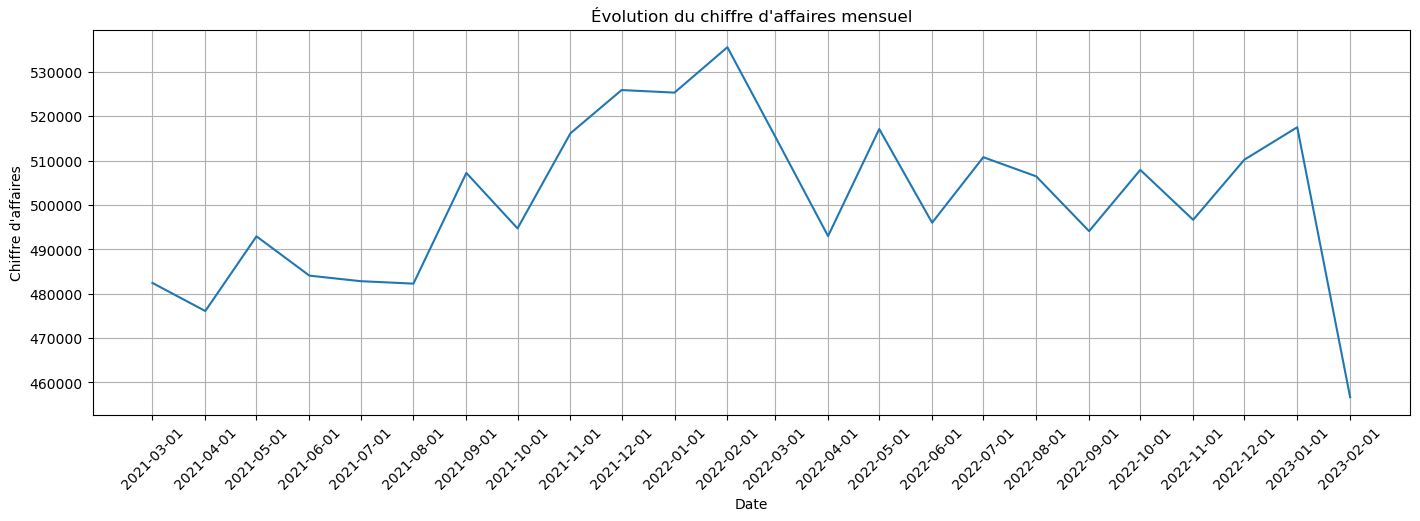

In [60]:
# évolution de chiffre d'affaire mensuel

plt.figure(figsize=(17,5))
plt.plot(ca_month.index.to_timestamp(), ca_month.values)

plt.title("Évolution du chiffre d'affaires mensuel")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.show()

Les graphiques mensuels me semble peu pertinents. en effet tous les moins n'ont pas le même nombre de jours.
De plus, les petites periodes à fort impact (quelques jours) peuvent être coupé en deux ne pas être bien
visible par moi. Je choisi donc le graphique journalier avec les moyens mobile de 7 et 30

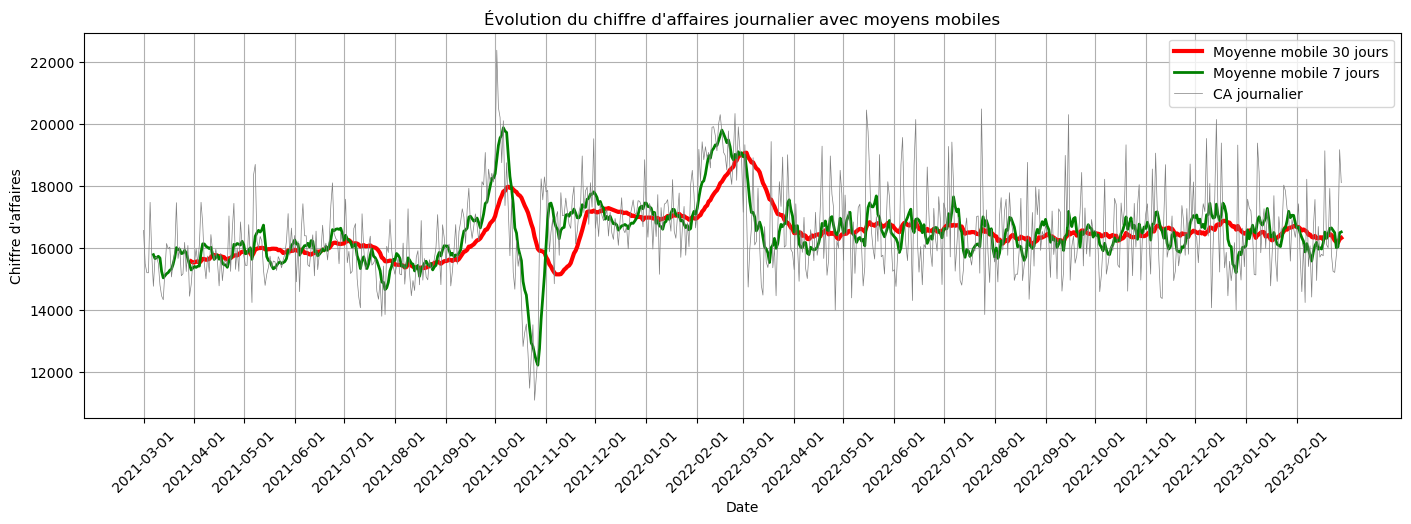

In [61]:
# graph journalier avec les 2 moyens mobile

ca_jour_mobile30 = ca_jour.rolling(window=30).mean()
ca_jour_mobile7 = ca_jour.rolling(window=7).mean()


plt.figure(figsize=(17,5))

plt.plot(ca_jour_mobile30.index, ca_jour_mobile30.values, label="Moyenne mobile 30 jours",
         linewidth=3, color="red")
plt.plot(ca_jour_mobile7.index, ca_jour_mobile7.values, label="Moyenne mobile 7 jours",
         linewidth=2, color="green")
plt.plot(ca_jour.index, ca_jour.values, label="CA journalier",
        linewidth=0.5, color="grey")

plt.title("Évolution du chiffre d'affaires journalier avec moyens mobiles")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
# plt.savefig("evolution_ca_journalier1.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        B- Evolution de chiffre d'affaires par catégorie
    </span>
</div>

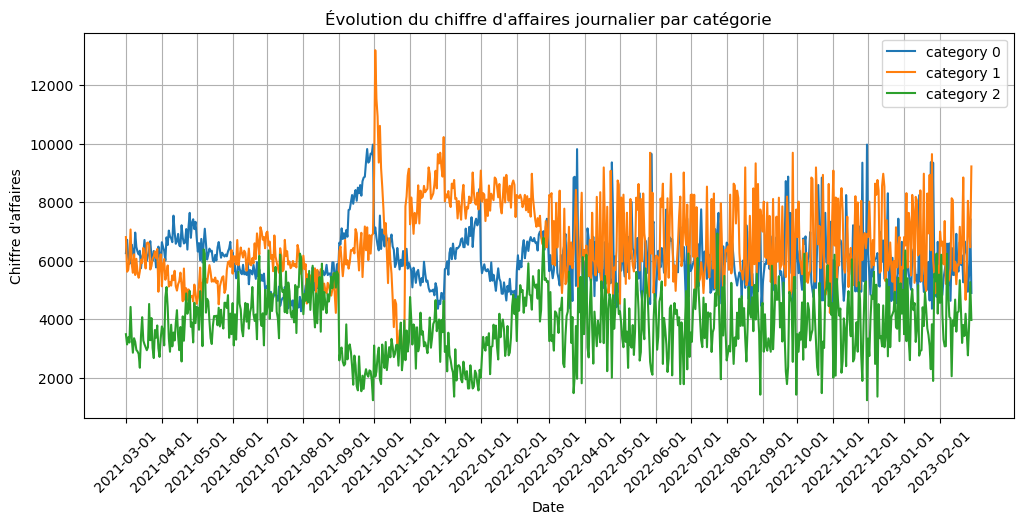

In [62]:
# d'abord le ca journalier simple par categorie

ca_jourcat0 = ventes[ventes.categ==0].groupby("day")["price"].sum()
ca_jourcat1 = ventes[ventes.categ==1].groupby("day")["price"].sum()
ca_jourcat2 = ventes[ventes.categ==2].groupby("day")["price"].sum()

plt.figure(figsize=(12,5))
plt.plot(ca_jourcat0.index, ca_jourcat0.values, label="category 0")
plt.plot(ca_jourcat1.index, ca_jourcat1.values, label="category 1")
plt.plot(ca_jourcat2.index, ca_jourcat2.values, label="category 2")

plt.title("Évolution du chiffre d'affaires journalier par catégorie")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
plt.show()

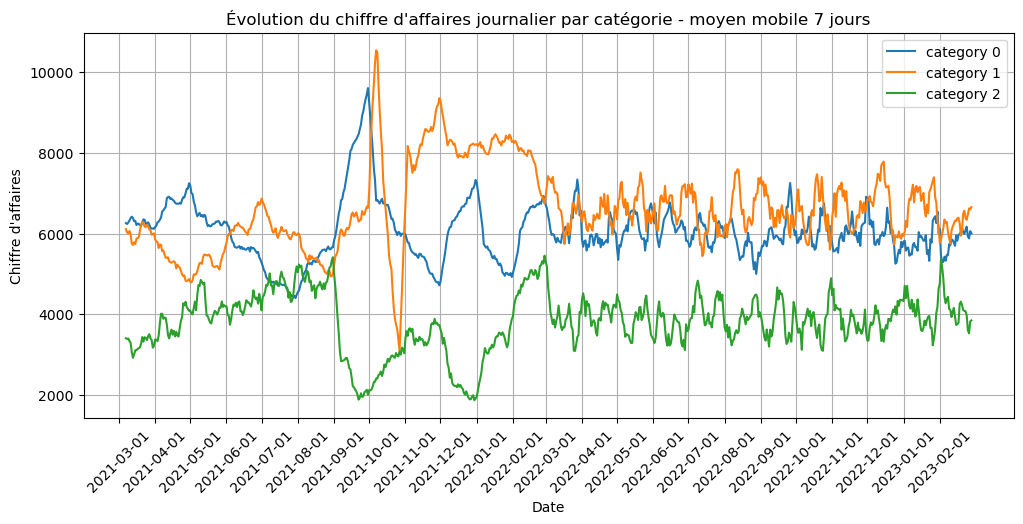

In [63]:
# maintenant le moyen mobile 7 jours par catégorie

ca_jourcat0 = ventes[ventes.categ==0].groupby("day")["price"].sum()
ca_jourcat0_mobile7 = ca_jourcat0.rolling(window=7).mean()

ca_jourcat1 = ventes[ventes.categ==1].groupby("day")["price"].sum()
ca_jourcat1_mobile7 = ca_jourcat1.rolling(window=7).mean()

ca_jourcat2 = ventes[ventes.categ==2].groupby("day")["price"].sum()
ca_jourcat2_mobile7 = ca_jourcat2.rolling(window=7).mean()

plt.figure(figsize=(12,5))
plt.plot(ca_jourcat0_mobile7.index, ca_jourcat0_mobile7.values, label="category 0")
plt.plot(ca_jourcat1_mobile7.index, ca_jourcat1_mobile7.values, label="category 1")
plt.plot(ca_jourcat2_mobile7.index, ca_jourcat2_mobile7.values, label="category 2")

plt.title("Évolution du chiffre d'affaires journalier par catégorie - moyen mobile 7 jours")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
plt.show()

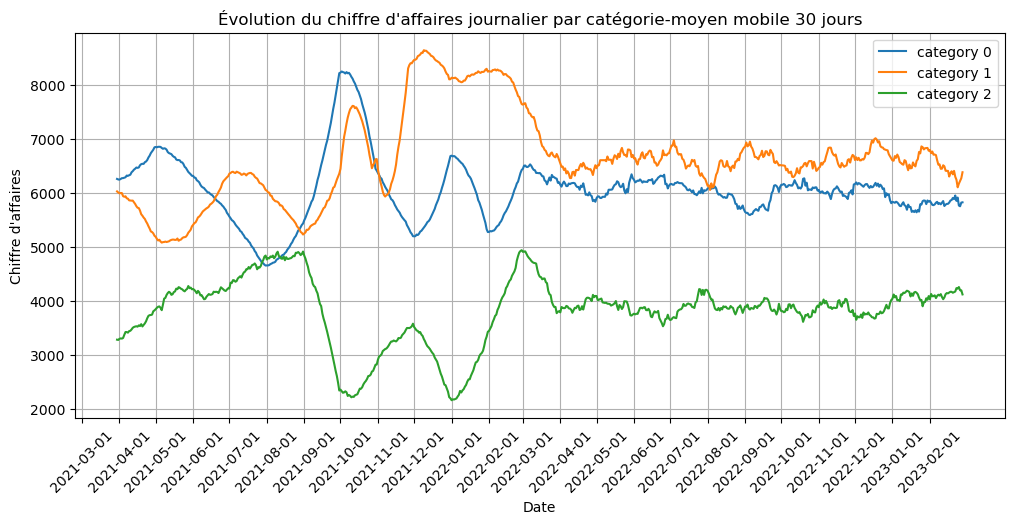

In [64]:
# faisons les moyens mobile 30 aussi pour voir
ca_jourcat0 = ventes[ventes.categ==0].groupby("day")["price"].sum()
ca_jourcat0_mobile30 = ca_jourcat0.rolling(window=30).mean()

ca_jourcat1 = ventes[ventes.categ==1].groupby("day")["price"].sum()
ca_jourcat1_mobile30 = ca_jourcat1.rolling(window=30).mean()

ca_jourcat2 = ventes[ventes.categ==2].groupby("day")["price"].sum()
ca_jourcat2_mobile30 = ca_jourcat2.rolling(window=30).mean()

plt.figure(figsize=(12,5))
plt.plot(ca_jourcat0_mobile30.index, ca_jourcat0_mobile30.values, label="category 0")
plt.plot(ca_jourcat1_mobile30.index, ca_jourcat1_mobile30.values, label="category 1")
plt.plot(ca_jourcat2_mobile30.index, ca_jourcat2_mobile30.values, label="category 2")

plt.title("Évolution du chiffre d'affaires journalier par catégorie-moyen mobile 30 jours")
plt.xlabel("Date")
plt.ylabel("Chiffre d'affaires")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
plt.legend()
# plt.savefig("evolution_ca_par_categorie.png", dpi=300, bbox_inches="tight")
plt.show()

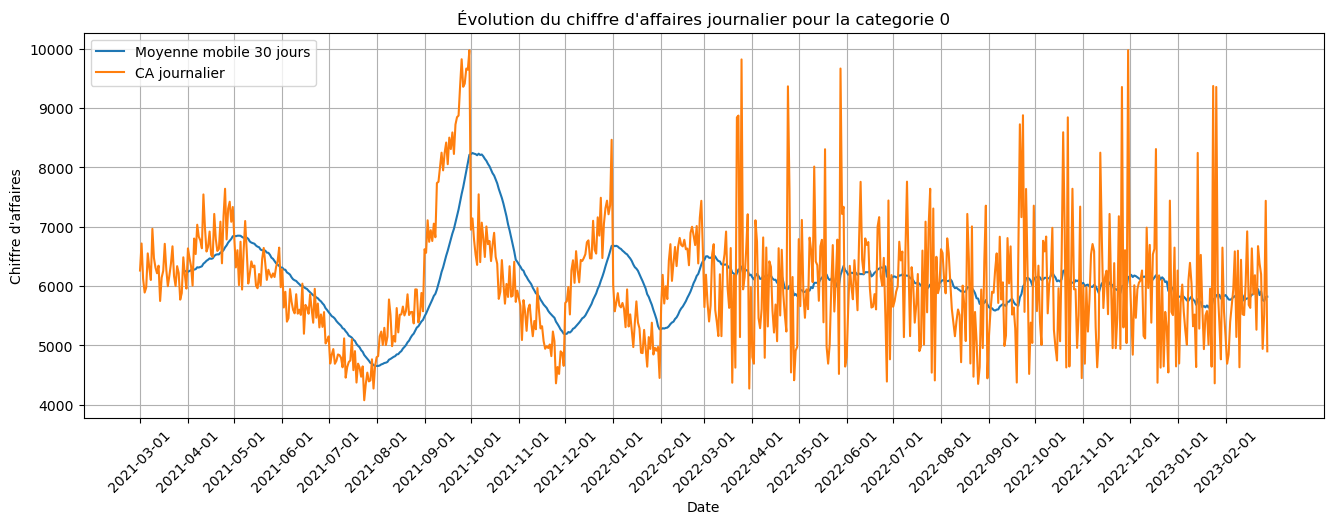

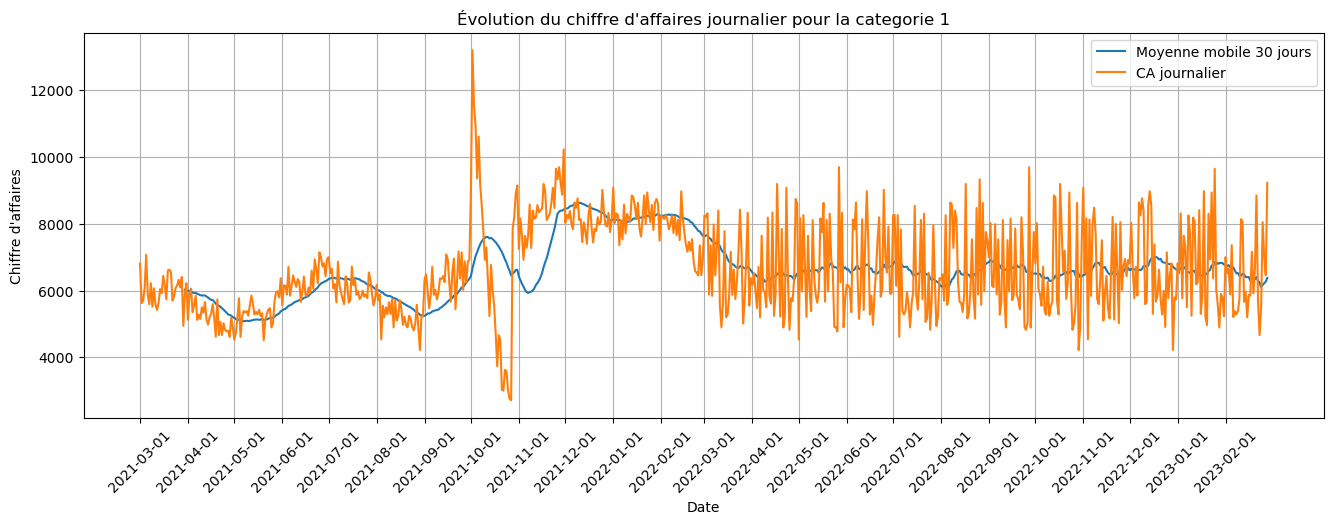

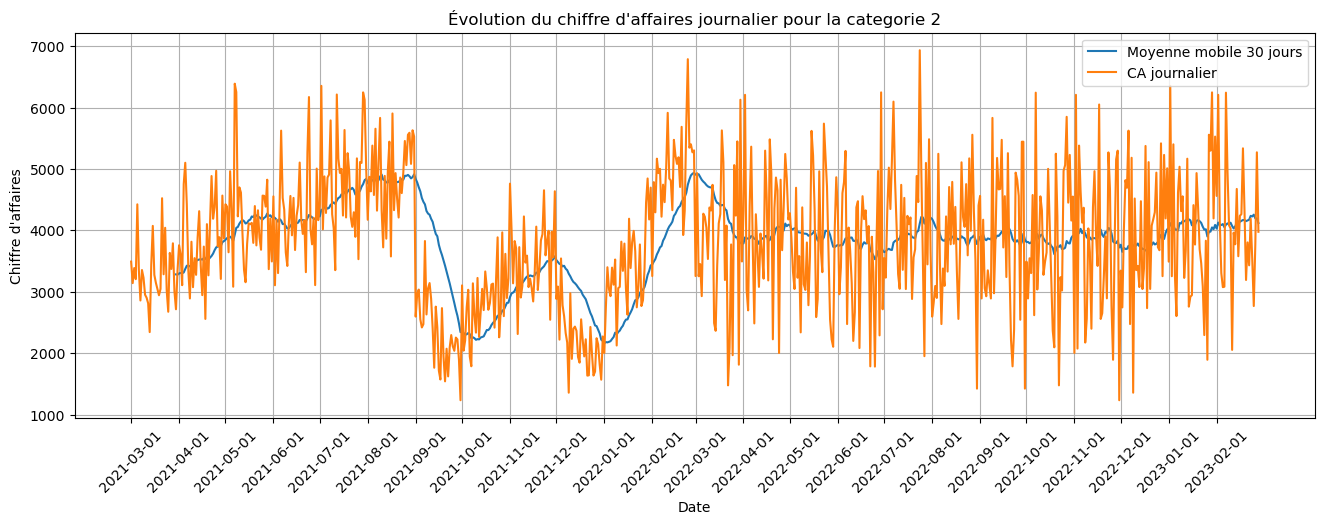

In [65]:
# évolution de chiffre d'affaire par catégorie

for category in [0, 1, 2]:
  
    ca_jourcat = ventes[ventes.categ==category].groupby("day")["price"].sum()
    ca_jour_mobilecat = ca_jourcat.rolling(window=30).mean()
    
    plt.figure(figsize=(16,5))
    plt.plot(ca_jour_mobilecat.index, ca_jour_mobilecat.values, label="Moyenne mobile 30 jours")
    plt.plot(ca_jourcat.index, ca_jourcat.values, label="CA journalier")
    plt.title(f"Évolution du chiffre d'affaires journalier pour la categorie {category}")
    plt.xlabel("Date")
    plt.ylabel("Chiffre d'affaires")
    plt.xticks(mois, rotation=45)
    plt.grid(axis="y")
    plt.grid(axis="x")
    plt.legend()
    plt.show() 

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        C - Evolution du nombre des transactions
    </span>
</div>

In [66]:
# nombre de transaction est la même chose que nombre de paniers ou nombre de sessions

In [67]:
# Je compte le nombre de sessions d’achat uniques par jour
transactions_day = ventes.groupby("day")["session_id"].nunique()
transactions_day.head()

day
2021-03-01    487
2021-03-02    471
2021-03-03    437
2021-03-04    449
2021-03-05    496
Name: session_id, dtype: int64

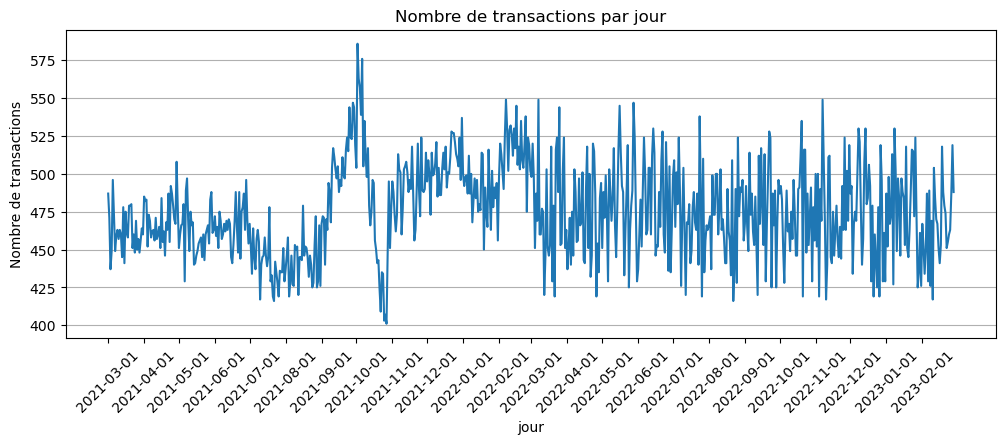

In [68]:
# pour avoir tous les mois sur le graphique, marqué le début du mois
mois = pd.date_range(transactions_day.index.min(), transactions_day.index.max(), freq="MS")

plt.figure(figsize=(12,4))
plt.plot(transactions_day.index, transactions_day.values, label="nombre des sessions d'achat par jour")
plt.title("Nombre de transactions par jour")
plt.xlabel("jour")
plt.ylabel("Nombre de transactions")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.show()

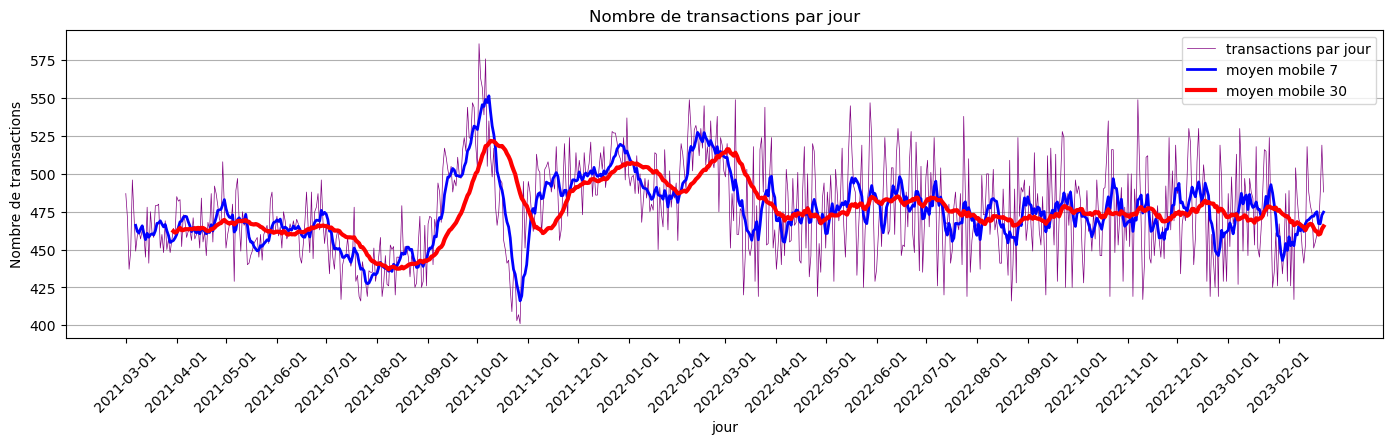

In [69]:
# avec les moyens mobiles
mois = pd.date_range(transactions_day.index.min(), transactions_day.index.max(), freq="MS")
transactions_day = ventes.groupby("day")["session_id"].nunique()
transactions_day_mobile7 = transactions_day.rolling(window=7).mean()
transactions_day_mobile30 = transactions_day.rolling(window=30).mean()

plt.figure(figsize=(17,4))
plt.plot(transactions_day.index, transactions_day.values, label="transactions par jour",
        linewidth=0.5, color="purple")
plt.plot(transactions_day_mobile7.index, transactions_day_mobile7.values, label="moyen mobile 7",
        linewidth=2, color="blue")
plt.plot(transactions_day_mobile30.index, transactions_day_mobile30.values, label="moyen mobile 30",
        linewidth=3, color="red")

plt.title("Nombre de transactions par jour")
plt.xlabel("jour")
plt.ylabel("Nombre de transactions")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.legend()
# plt.savefig("evolution_transactions.png", dpi=300, bbox_inches="tight")
plt.show()


<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        D - Evolution du nombre de livre vendus
    </span>
</div>

In [70]:
# je fait une table qui dit, pour chaque jour, combien de livre ont été vendu

In [71]:
produit_jour = ventes.groupby("day")["id_prod"].count()

In [72]:
produit_jour.head()

day
2021-03-01    962
2021-03-02    939
2021-03-03    911
2021-03-04    903
2021-03-05    943
Name: id_prod, dtype: int64

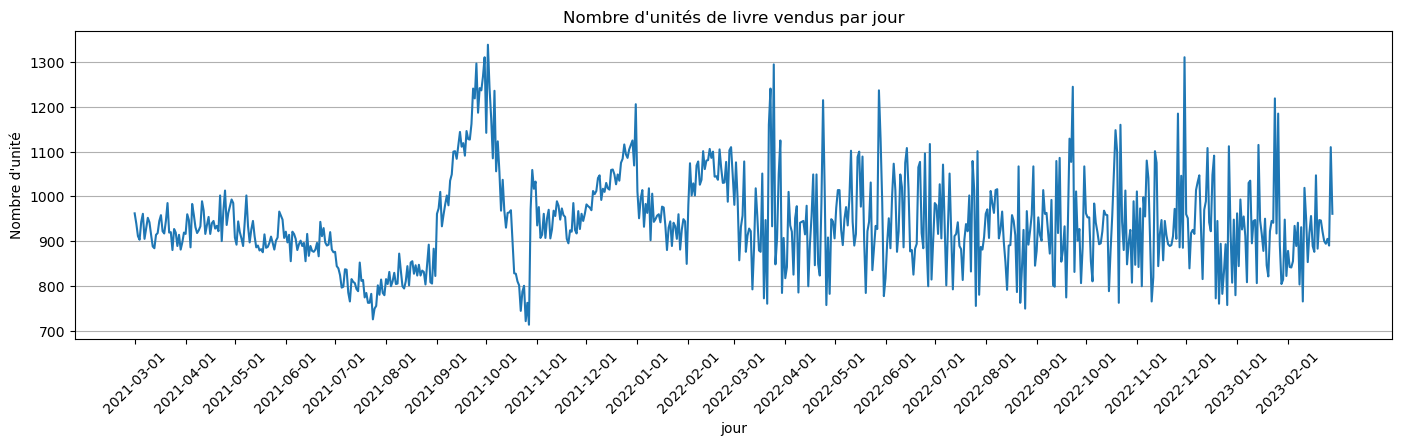

In [73]:
mois = pd.date_range(produit_jour.index.min(), produit_jour.index.max(), freq="MS")

plt.figure(figsize=(17,4))
plt.plot(produit_jour.index, produit_jour.values, label="nombre d'unités vendus par jour")
plt.title("Nombre d'unités de livre vendus par jour")
plt.xlabel("jour")
plt.ylabel("Nombre d'unité")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.show()

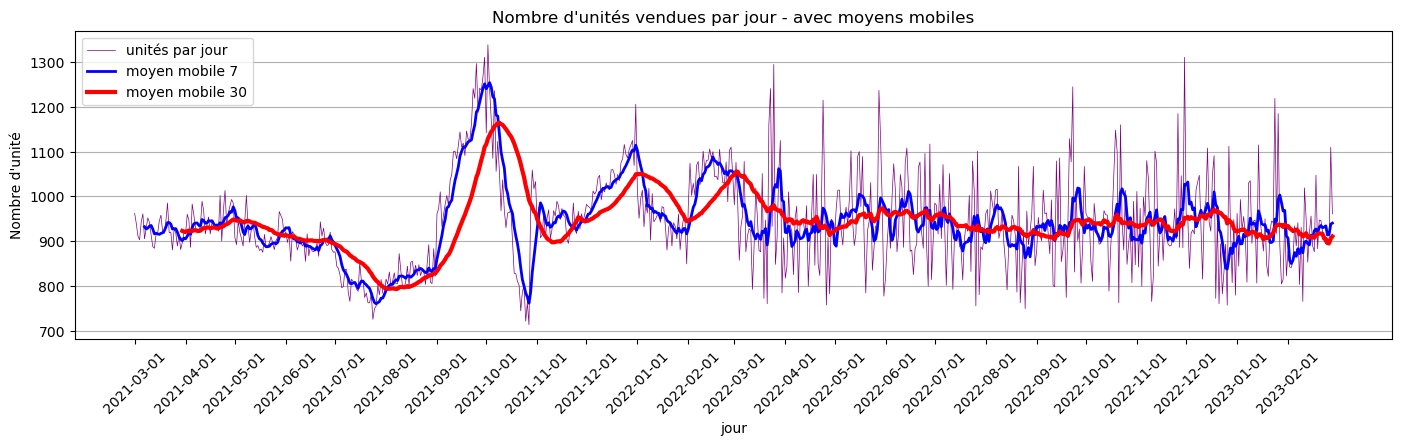

In [74]:
# nombre d'unité de livre vendu par jour avec les moyens mobile
produit_jour = ventes.groupby("day")["id_prod"].count()
produit_jour_mobile7 = produit_jour.rolling(window=7).mean()
produit_jour_mobile30 = produit_jour.rolling(window=30).mean()

mois = pd.date_range(produit_jour.index.min(), produit_jour.index.max(), freq="MS")

plt.figure(figsize=(17,4))
plt.plot(produit_jour.index, produit_jour.values, label="unités par jour",
        linewidth=0.5, color="purple")
plt.plot(produit_jour_mobile7.index, produit_jour_mobile7.values, label="moyen mobile 7",
        linewidth=2, color="blue")
plt.plot(produit_jour_mobile30.index, produit_jour_mobile30.values, label="moyen mobile 30",
        linewidth=3, color="red")

plt.title("Nombre d'unités vendues par jour - avec moyens mobiles")
plt.xlabel("jour")
plt.ylabel("Nombre d'unité")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.legend()
# plt.savefig("evolution_nbproduit.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        E - Evolution du nombre de clients
    </span>
</div>

In [75]:
# un tableau avec des clients uniques par mois
clients_mois = ventes.groupby("month")["client_id"].nunique()

In [76]:
clients_mois.head()

month
2021-03    5676
2021-04    5674
2021-05    5644
2021-06    5659
2021-07    5672
Freq: M, Name: client_id, dtype: int64

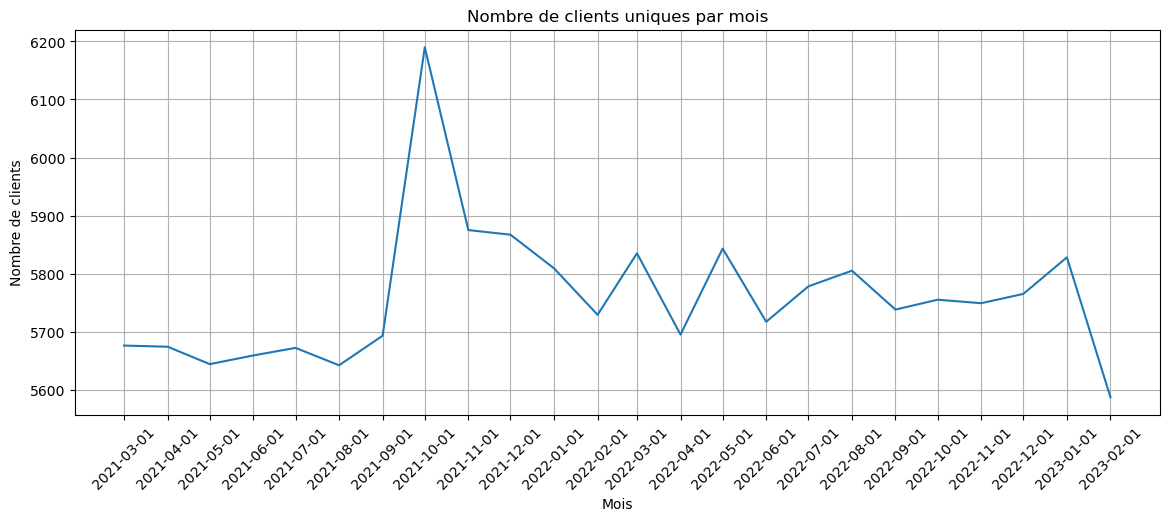

In [77]:
clients_mois = ventes.groupby("month")["client_id"].nunique()

mois = clients_mois.index.to_timestamp()

plt.figure(figsize=(14,5))
plt.plot(mois, clients_mois.values)

plt.title("Nombre de clients uniques par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre de clients")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.grid(axis="x")
# plt.savefig("clients par mois.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> Graphique ensemble des évolutions </span>
</div>

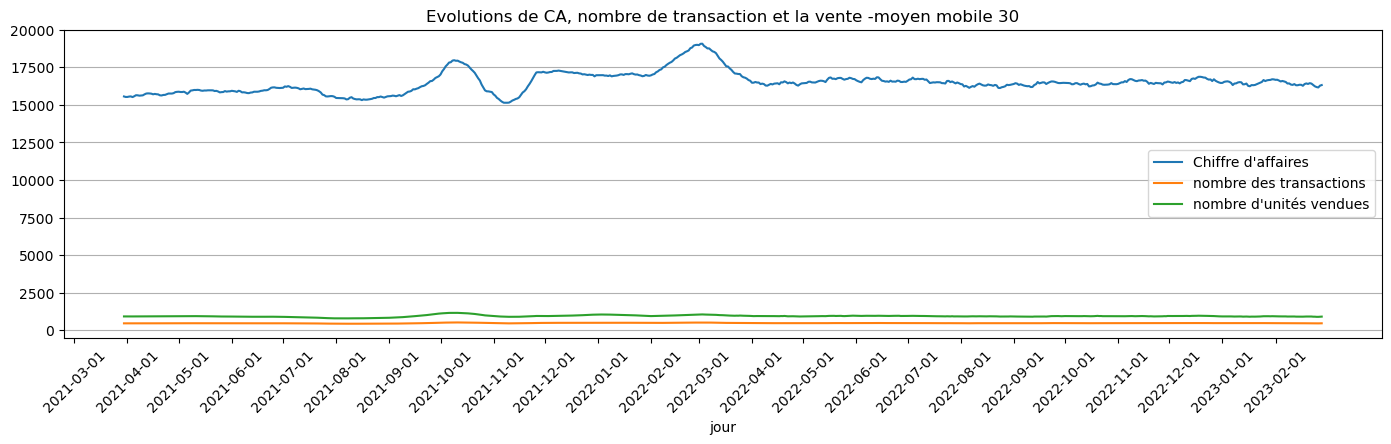

In [78]:
ca_jour = ventes.groupby("day")["price"].sum()
ca_jour_mobile30 = ca_jour.rolling(window=30).mean()

transactions_day = ventes.groupby("day")["session_id"].nunique()
transactions_day_mobile30 = transactions_day.rolling(window=30).mean()

produit_jour = ventes.groupby("day")["id_prod"].count()
produit_jour_mobile30 = produit_jour.rolling(window=30).mean()

plt.figure(figsize=(17,4))
plt.plot(ca_jour_mobile30.index, ca_jour_mobile30.values, label="Chiffre d'affaires")
plt.plot(transactions_day_mobile30.index, transactions_day_mobile30.values, label="nombre des transactions")
plt.plot(produit_jour_mobile30.index, produit_jour_mobile30.values, label="nombre d'unités vendues")

plt.title("Evolutions de CA, nombre de transaction et la vente -moyen mobile 30")
plt.xlabel("jour")

plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.legend()
plt.show()


le graphique n'est pas lisible à cause des différences d'unité.
il faut tout ramener à base 100 en choisissant la valeur de référence

In [79]:
ca_jour = ventes.groupby("day")["price"].sum()
ca_jour_mobile30 = ca_jour.rolling(window=30).mean()
ca_jour_mobile30 = ca_jour_mobile30.dropna()

transactions_day = ventes.groupby("day")["session_id"].nunique()
transactions_day_mobile30 = transactions_day.rolling(window=30).mean()
transactions_day_mobile30 = transactions_day_mobile30.dropna()

produit_jour = ventes.groupby("day")["id_prod"].count()
produit_jour_mobile30 = produit_jour.rolling(window=30).mean()
produit_jour_mobile30 = produit_jour_mobile30.dropna()

# j'ai vérifié: après supression des lignes vides causé par les moyens mobiles
# toutes les séries commencent le même jour: 2021-03-30
# je prend donc ce premier jour comme la valeur de référence
# et je calculs les index base 100

ca_base100 = (ca_jour_mobile30 / ca_jour_mobile30.iloc[0] * 100 )
transactions_base100 = (transactions_day_mobile30 / transactions_day_mobile30.iloc[0] * 100 )
produit_base100 = (produit_jour_mobile30 / produit_jour_mobile30.iloc[0] * 100)

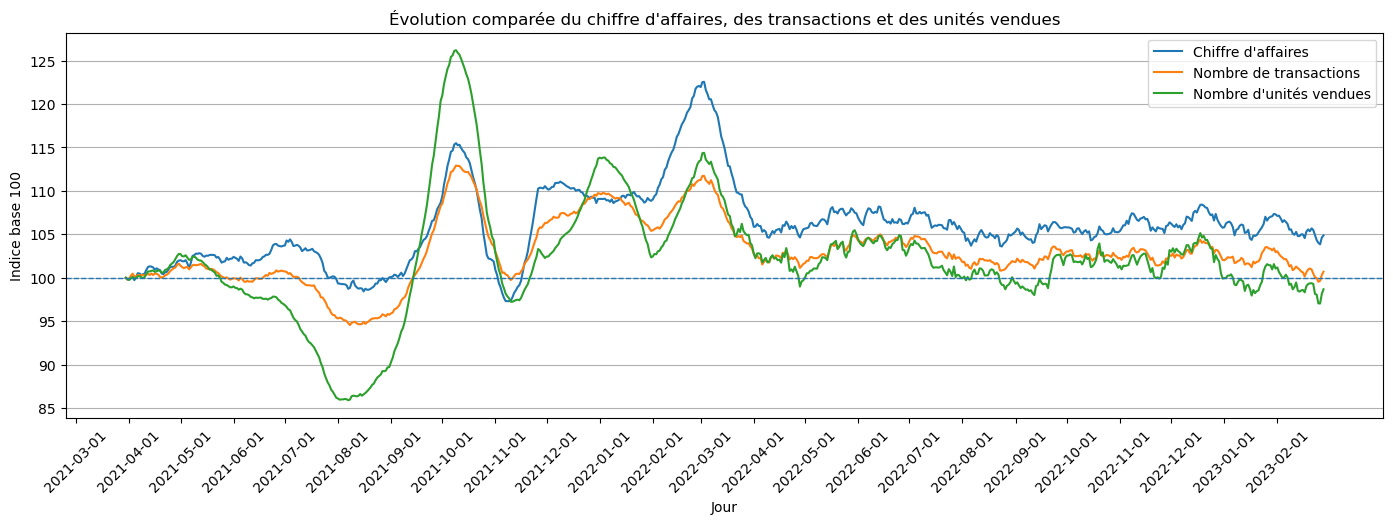

In [80]:
# graphique des 3 mesures ensemble base 100
plt.figure(figsize=(17, 5))

plt.plot(ca_base100.index, ca_base100.values, label="Chiffre d'affaires")
plt.plot(transactions_base100.index, transactions_base100.values, label="Nombre de transactions")
plt.plot(produit_base100.index, produit_base100.values, label="Nombre d'unités vendues")

plt.axhline(100, linestyle="--", linewidth=1)

plt.title(
    "Évolution comparée du chiffre d'affaires, "
    "des transactions et des unités vendues"
)
plt.xlabel("Jour")
plt.ylabel("Indice base 100")
plt.xticks(mois, rotation=45)
plt.grid(axis="y")
plt.legend()
plt.savefig("3_evolutions.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border: 2px solid magenta; padding: 10px;">
<span style="color: magenta; font-size: 24px; font-weight: bold"> Analyse des produits
</span>
</div>

In [81]:
# je fais un dataframe de produits avec leur chiffre d'affaire
# il s'agit des produits déja vendu, car la base est la table des transactions
# les produit jamais vendu ne sont pas pris en compte ici

produits_ca = (ventes.groupby("id_prod")["price"].sum().sort_values(ascending=False)
               .rename("chiffre_affaires").reset_index()
              )
              

In [82]:
produits_ca.head()

,id_prod,chiffre_affaires
0,2_159,94893.50
1,2_135,69334.95
2,2_112,65407.76
3,2_102,60736.78
4,2_209,56971.86


In [83]:
# je fusionne cela avec table products pour avoir les prix et categories

produits_ca = produits_ca.merge(products, on="id_prod", how="left")

In [84]:
produits_ca.head()

,id_prod,chiffre_affaires,price,categ
0,2_159,94893.50,145.99,2
1,2_135,69334.95,68.99,2
2,2_112,65407.76,67.57,2
3,2_102,60736.78,59.14,2
4,2_209,56971.86,69.99,2


In [85]:
produits_ca = produits_ca.sort_values("chiffre_affaires",ascending=False)

In [86]:
# top 10 des produits rentables
produits_ca.head(10)

,id_prod,chiffre_affaires,price,categ
0,2_159,94893.50,145.99,2
1,2_135,69334.95,68.99,2
2,2_112,65407.76,67.57,2
3,2_102,60736.78,59.14,2
4,2_209,56971.86,69.99,2
5,1_395,56617.47,28.99,1
6,1_369,56136.60,23.99,1
7,2_110,53846.25,62.25,2
8,1_383,53834.43,28.99,1
9,1_414,53522.18,23.83,1


In [87]:
# flop 10
produits_ca.tail(10)

,id_prod,chiffre_affaires,price,categ
3255,0_1840,2.56,1.28,0
3256,0_898,2.54,1.27,0
3257,0_1498,2.48,2.48,0
3258,0_1728,2.27,2.27,0
3260,0_1601,1.99,1.99,0
3259,0_541,1.99,1.99,0
3261,0_807,1.99,1.99,0
3262,0_1653,1.98,0.99,0
3263,0_1284,1.38,1.38,0
3264,0_1539,0.99,0.99,0


<div style="border: 2px solid magenta; padding: 10px;">
<span style="color: magenta; font-size: 24px; font-weight: bold"> Le poids des clients
</span>
</div>

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
       Les clients les plus rentables
    </span>
</div>

In [88]:
# on regarde la table clients_stats pour voir qui sont les 10 clients les plus rentables

In [89]:
clients_stats.sort_values("montant_total", ascending=False).head(10)

,client_id,sex,birth,age,tranche_age10,tranche_age20,montant_total,nombre_achats,nombre_produits,panier_moyen
677,c_1609,m,1980,43,41-50 ans,31-50 ans,326039.89,10997,25586,29.65
4388,c_4958,m,1999,24,21-30 ans,17-30 ans,290227.03,3851,5222,75.36
6337,c_6714,f,1968,55,51-60 ans,51-70 ans,153918.60,2620,9199,58.75
2724,c_3454,m,1969,54,51-60 ans,51-70 ans,114110.57,5571,6793,20.48
634,c_1570,f,1979,44,41-50 ans,31-50 ans,5285.82,159,370,33.24
2513,c_3263,f,1985,38,31-40 ans,31-50 ans,5276.87,143,403,36.90
1268,c_2140,f,1977,46,41-50 ans,31-50 ans,5260.18,147,405,35.78
2108,c_2899,f,1994,29,21-30 ans,17-30 ans,5214.05,69,105,75.57
7006,c_7319,f,1974,49,41-50 ans,31-50 ans,5155.77,145,371,35.56
7715,c_7959,f,1974,49,41-50 ans,31-50 ans,5135.75,148,372,34.70


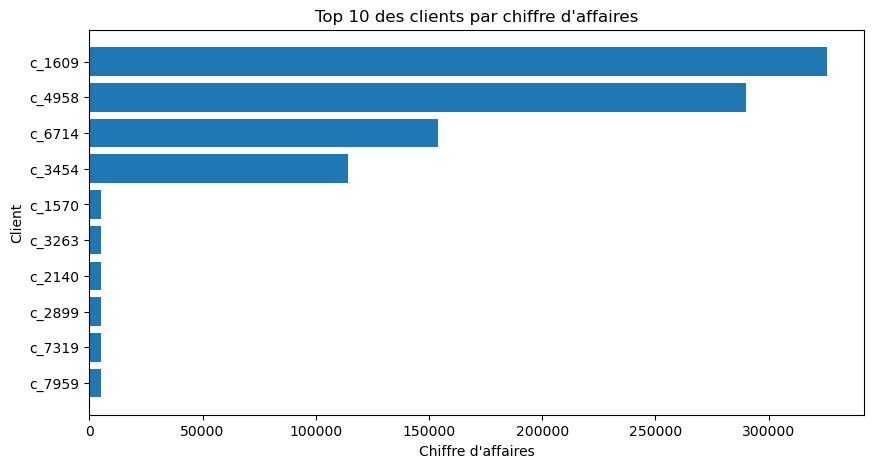

In [90]:
top_clients = clients_stats.sort_values("montant_total", ascending=False).head(10)

plt.figure(figsize=(10,5))

plt.barh(
    top_clients["client_id"][::-1],
    top_clients["montant_total"][::-1]
)

plt.title("Top 10 des clients par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Client")
# plt.savefig("Top 10 des clients.png", dpi=300, bbox_inches="tight")
plt.show()

**Ici il faut séparer les 4 clients B to B des autres**

**utiliser à partir de maintenant les tables**

**clients_stats**

**clients_stats_b2b**

**clients_stats_b2c**

**ventes_b2b**

**ventes_b2c**

In [91]:
# part des B to B dans le chiffre d'affaire totale

ca_total = clients_stats["montant_total"].sum()
ca_b2b = clients_stats_b2b["montant_total"].sum()

part_b2b = ca_b2b / ca_total * 100

print(f"CA total : {ca_total:,.2f} €")
print(f"CA des 4 clients BtoB : {ca_b2b:,.2f} €")
print(f"Part des BtoB dans le CA : {part_b2b:.2f} %")

CA total : 12,027,663.10 €
CA des 4 clients BtoB : 884,296.09 €
Part des BtoB dans le CA : 7.35 %


In [92]:
# part dans les nombre des produits acheté
produits_total = clients_stats["nombre_produits"].sum()
produits_b2b = clients_stats_b2b["nombre_produits"].sum()

part_produits_b2b = produits_b2b / produits_total * 100

print(f"Produits achetés au total : {produits_total}")
print(f"Produits achetés par les 4 BtoB : {produits_b2b}")
print(f"Part des B2B dans les produits achetés : {part_produits_b2b:.2f} %")

Produits achetés au total : 687534
Produits achetés par les 4 BtoB : 46800
Part des B2B dans les produits achetés : 6.81 %


<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        La répartition des dépenses des clients
    </span>
</div>

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> La courbe de lorenz </span>
</div>

La courbe de Lorenz permet d’observer la concentration du chiffre d’affaires entre les clients. Plus la courbe s’éloigne de la diagonale, plus le chiffre d’affaires est concentré sur une petite partie des clients.

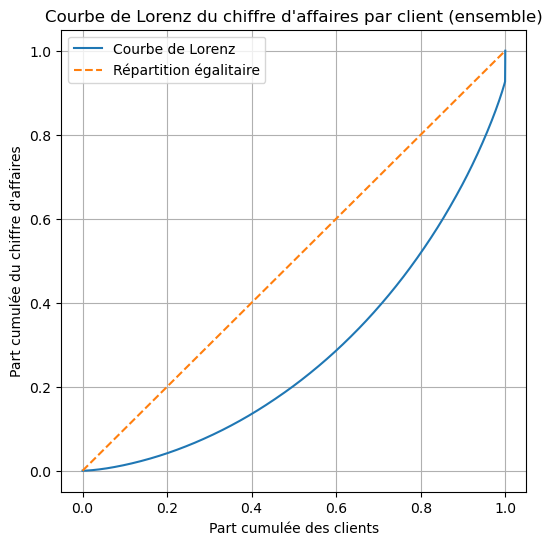

In [93]:
# courbe de Lorenz, ensemble des clients
ca_clients_lorenz = clients_stats["montant_total"].sort_values()

lorenz = ca_clients_lorenz.cumsum() / ca_clients_lorenz.sum()
lorenz = pd.concat([pd.Series([0]), lorenz.reset_index(drop=True)])

x = np.linspace(0, 1, len(lorenz))

plt.figure(figsize=(6,6))

plt.plot(x, lorenz, label="Courbe de Lorenz")
plt.plot([0,1], [0,1], linestyle="--", label="Répartition égalitaire")

plt.title("Courbe de Lorenz du chiffre d'affaires par client (ensemble)")
plt.xlabel("Part cumulée des clients")
plt.ylabel("Part cumulée du chiffre d'affaires")
plt.legend()
plt.grid()
#plt.savefig("lorenz ca ensemble.png", dpi=300, bbox_inches="tight")
plt.show()

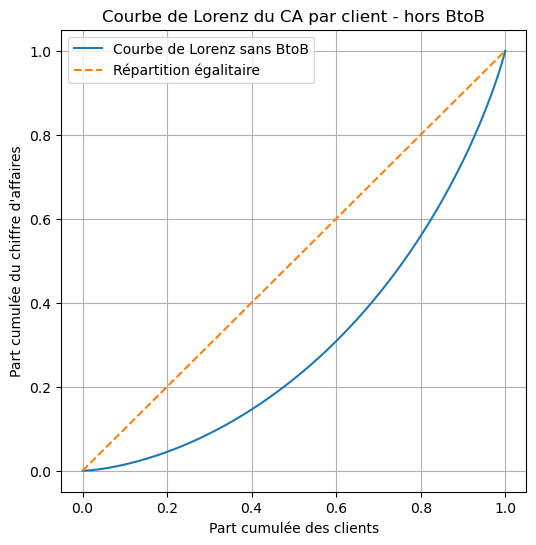

In [94]:
# courbe de lorenz sans les B to B
ca_clients_lorenz_b2c = clients_stats_b2c["montant_total"].sort_values()

lorenz_b2c = ca_clients_lorenz_b2c.cumsum() / ca_clients_lorenz_b2c.sum()
lorenz_b2c = pd.concat([pd.Series([0]), lorenz_b2c.reset_index(drop=True)])

x_b2c = np.linspace(0, 1, len(lorenz_b2c))

plt.figure(figsize=(6,6))

plt.plot(x_b2c, lorenz_b2c, label="Courbe de Lorenz sans BtoB")
plt.plot([0,1], [0,1], linestyle="--", label="Répartition égalitaire")

plt.title("Courbe de Lorenz du CA par client - hors BtoB")
plt.xlabel("Part cumulée des clients")
plt.ylabel("Part cumulée du chiffre d'affaires")
plt.legend()
plt.grid()
# plt.savefig("lorenz ca hors BtoB.png", dpi=300, bbox_inches="tight")
plt.show()

Après exclusion des 4 clients BtoB, la courbe de Lorenz permet d’observer la concentration du chiffre d’affaires au sein de la clientèle BtoC.

<div style="border-left: 2px solid purple; padding: 8px"> 
    <span style="font-size: 16px; font-weight: bold; color :purple; "> Indice de Gini </span>
</div>

In [95]:
def coefficient_gini(valeurs):
    valeurs = np.sort(valeurs)
    n = len(valeurs)
    cumul = np.cumsum(valeurs)
    return (n + 1 - 2 * np.sum(cumul) / cumul[-1]) / n

In [96]:
gini_total = (coefficient_gini(clients_stats["montant_total"])).round(3)
gini_total

np.float64(0.442)

In [97]:
gini_b2c = (coefficient_gini(clients_stats_b2c["montant_total"])).round(3)
gini_b2c

np.float64(0.398)

In [98]:
print(f"Coefficient de Gini avec BtoB : {gini_total:.3f}")
print(f"Coefficient de Gini sans BtoB : {gini_b2c:.3f}")

Coefficient de Gini avec BtoB : 0.442
Coefficient de Gini sans BtoB : 0.398


Le coefficient de Gini complète la courbe de Lorenz en quantifiant la concentration du chiffre d'affaires entre les clients. Plus il est proche de 1, plus le chiffre d'affaires est concentré sur un petit nombre de clients.

<div style="border: 2px solid magenta; padding: 10px;">
<span style="color: magenta; font-size: 24px; font-weight: bold"> Comportement des clients
</span>
</div>

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
       A- Charactéristiques gloables
    </span>
</div>

In [99]:
clients_stats_b2b.head()

,client_id,sex,birth,age,tranche_age10,tranche_age20,montant_total,nombre_achats,nombre_produits,panier_moyen
677,c_1609,m,1980,43,41-50 ans,31-50 ans,326039.89,10997,25586,29.65
2724,c_3454,m,1969,54,51-60 ans,51-70 ans,114110.57,5571,6793,20.48
4388,c_4958,m,1999,24,21-30 ans,17-30 ans,290227.03,3851,5222,75.36
6337,c_6714,f,1968,55,51-60 ans,51-70 ans,153918.60,2620,9199,58.75


In [100]:
age_table = (
    clients_stats_b2c["age"]
    .value_counts()
    .sort_index()
    .reset_index()
)

age_table.columns = ["age", "nombre_clients"]

age_table

,age,nombre_clients
0,19,437
1,20,145
2,21,145
3,22,125
4,23,136
...,...,...
71,90,8
72,91,6
73,92,4
74,93,4


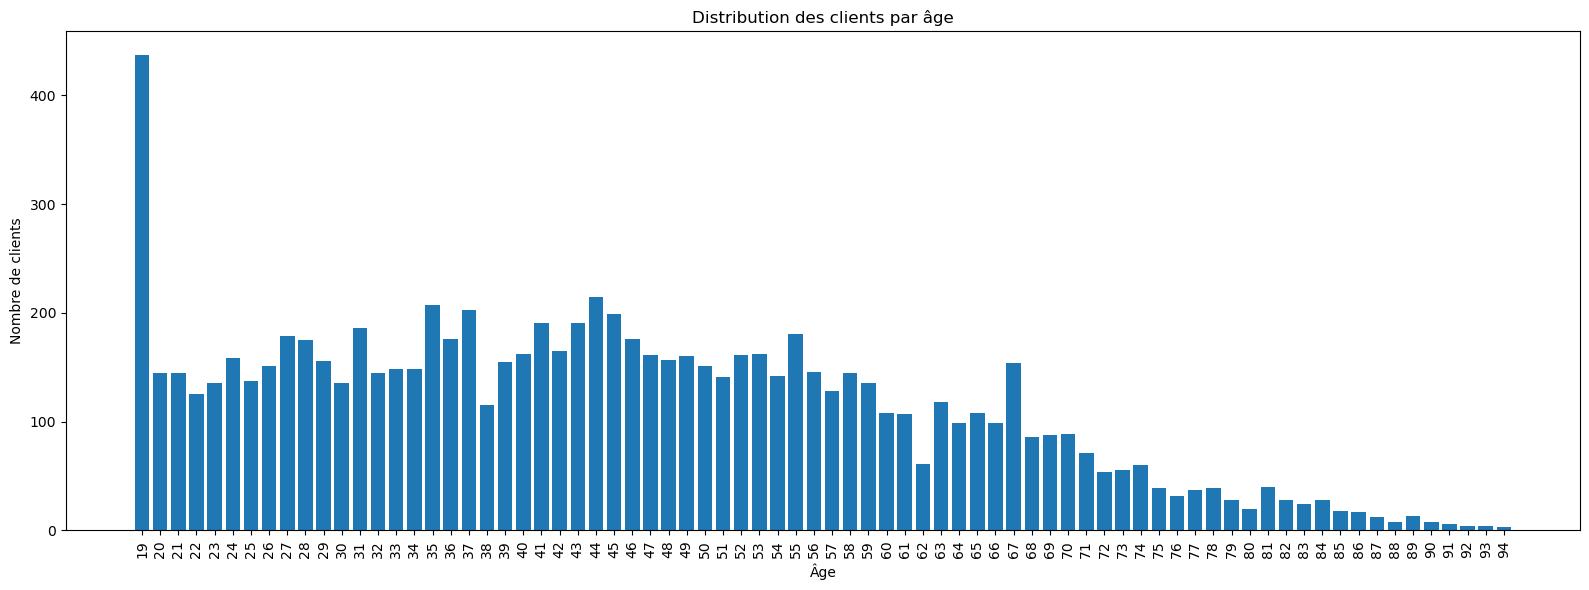

In [101]:
import matplotlib.pyplot as plt

effectifs_age = (
    clients_stats["age"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(16, 6))

plt.bar(
    effectifs_age.index.astype(str),
    effectifs_age.values
)

plt.title("Distribution des clients par âge")
plt.xlabel("Âge")
plt.ylabel("Nombre de clients")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

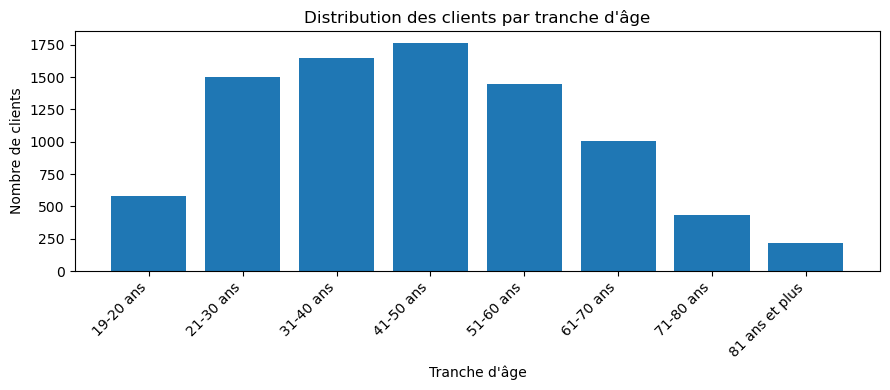

In [102]:
effectifs_tranches = (
    clients_stats["tranche_age10"]
    .value_counts(sort=False)
)

plt.figure(figsize=(9, 4))

plt.bar(
    effectifs_tranches.index.astype(str),
    effectifs_tranches.values
)

plt.title("Distribution des clients par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Nombre de clients")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

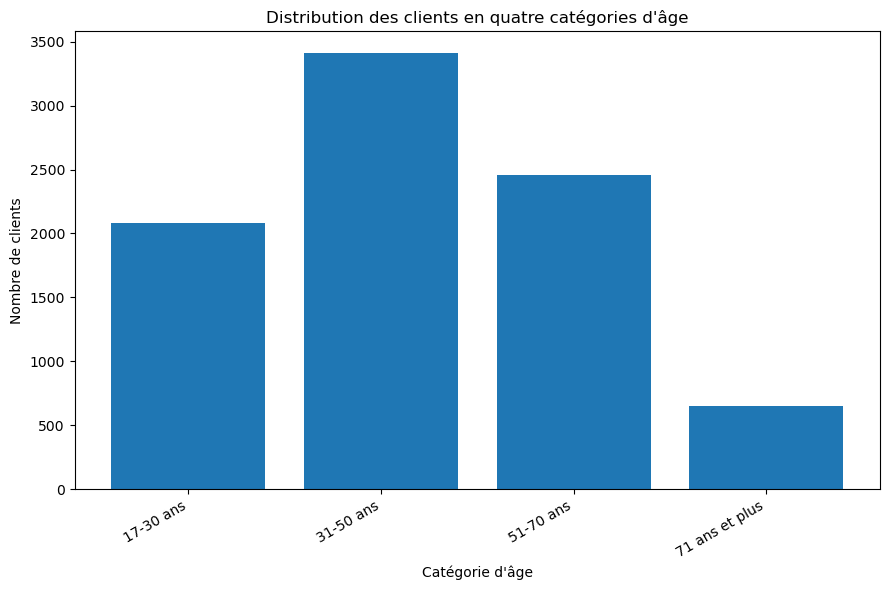

In [103]:
effectifs_tranches_4 = (
    clients_stats["tranche_age20"]
    .value_counts(sort=False)
)

plt.figure(figsize=(9, 6))

plt.bar(
    effectifs_tranches_4.index.astype(str),
    effectifs_tranches_4.values
)

plt.title("Distribution des clients en quatre catégories d'âge")
plt.xlabel("Catégorie d'âge")
plt.ylabel("Nombre de clients")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

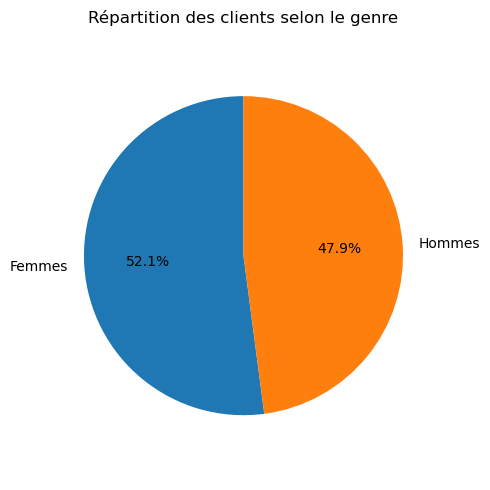

In [104]:
# proportion des hommes et des femmes
import matplotlib.pyplot as plt

repartition_sexe = (
    clients_stats["sex"]
    .value_counts()
    .reindex(["f", "m"])
)

plt.figure(figsize=(5, 5))

plt.pie(
    repartition_sexe.values,
    labels=["Femmes", "Hommes"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Répartition des clients selon le genre")
plt.axis("equal")
plt.tight_layout()
plt.show()


In [105]:
#répartition selon l'age et sexe

In [106]:
effectifs_age_sexe = pd.crosstab(
    clients_stats["tranche_age10"],
    clients_stats["sex"]
)

effectifs_age_sexe

sex,f,m
tranche_age10,,
19-20 ans,296,286
21-30 ans,771,728
31-40 ans,843,802
41-50 ans,930,836
51-60 ans,750,700
61-70 ans,517,492
71-80 ans,245,191
81 ans et plus,127,86


In [107]:
effectifs_age_sexe = effectifs_age_sexe.reindex(
    columns=["f", "m"],
    fill_value=0
)

effectifs_age_sexe.columns = ["Femmes", "Hommes"]

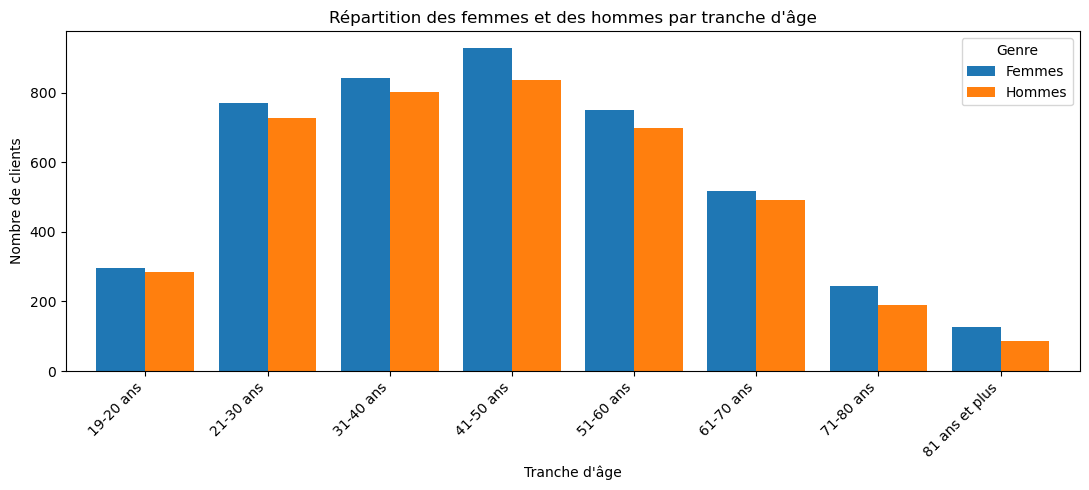

In [108]:
ax = effectifs_age_sexe.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)

ax.set_title("Répartition des femmes et des hommes par tranche d'âge")
ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Nombre de clients")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Genre")
plt.tight_layout()
# plt.savefig("age_genre.png", dpi=300, bbox_inches="tight")
plt.show()

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        B- Lien entre le genre et la catégorie de livre
    </span>
</div>

In [109]:
from scipy.stats import chi2_contingency

In [110]:
#table des effectifs brutes - par genre et par catégorie
# on utilise la table vente_b2c
# où il y a une ligne par produit vendu qui montre la catégorie et le genre du client

table_contingence = pd.crosstab(
    ventes_b2c["sex"],
    ventes_b2c["categ"]
)

table_contingence

categ,0,1,2
sex,,,
f,200793,115721,16980
m,186488,104884,15868


In [111]:
table_contingence.index = ["Femmes", "Hommes"]
table_contingence.columns = [
    "Catégorie 0",
    "Catégorie 1",
    "Catégorie 2"
]

table_contingence

,Catégorie 0,Catégorie 1,Catégorie 2
Femmes,200793,115721,16980
Hommes,186488,104884,15868


In [112]:
# pour plus de clarté, je calcul le pourcentage de chaque catégorie au sein de chanque sex

table_pourcentages = (
    table_contingence
    .div(table_contingence.sum(axis=1), axis=0)
    * 100
)

table_pourcentages.round(2)

,Catégorie 0,Catégorie 1,Catégorie 2
Femmes,60.21,34.70,5.09
Hommes,60.70,34.14,5.16


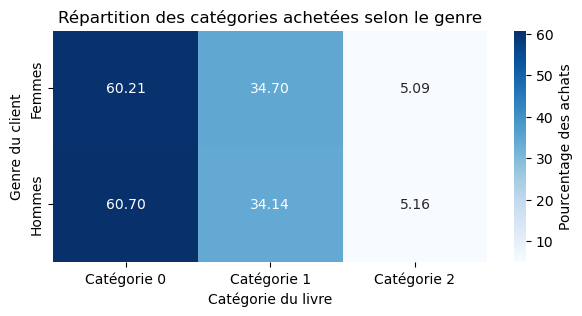

In [113]:
# Heatmap des pourcentages
plt.figure(figsize=(7, 3))

sns.heatmap(
    table_pourcentages,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar_kws={"label": "Pourcentage des achats"}
)

plt.title("Répartition des catégories achetées selon le genre")
plt.xlabel("Catégorie du livre")
plt.ylabel("Genre du client")

plt.show()

In [114]:
# réaliser le test khi 2

chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(
    table_contingence
)

print(f"Statistique du khi² : {chi2:.3f}")
print(f"Degrés de liberté : {ddl}")
print(f"P-value : {p_value:.6e}")

Statistique du khi² : 22.669
Degrés de liberté : 2
P-value : 1.195593e-05


In [115]:
# V de Cramer pour compléter le test khi2

n = table_contingence.to_numpy().sum()

nombre_lignes, nombre_colonnes = table_contingence.shape

v_cramer = np.sqrt(
    (chi2 / n)
    / min(nombre_lignes - 1, nombre_colonnes - 1)
)

print(f"V de Cramér : {v_cramer:.4f}")

V de Cramér : 0.0059


<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        C - Lien entre l'age et le montant total d'achat
    </span>
</div>

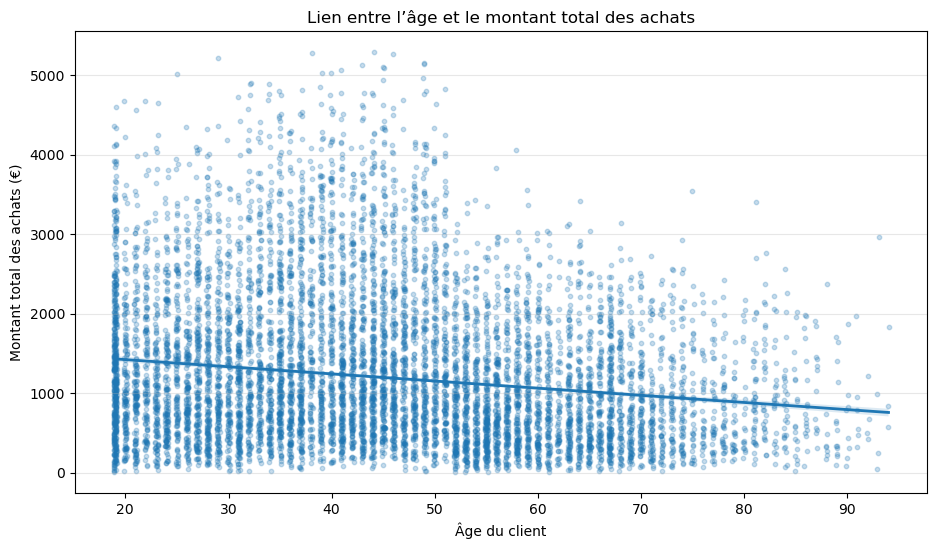

In [116]:
# nuage des points entre l'age et le montant total
plt.figure(figsize=(11, 6))

sns.regplot(
    data=clients_stats_b2c,
    x="age",
    y="montant_total",
    robust=True,
    x_jitter=0.15,
    scatter_kws={
        "s": 10,
        "alpha": 0.25
    },
    line_kws={
        "linewidth": 2
    }
)

plt.title("Lien entre l’âge et le montant total des achats")
plt.xlabel("Âge du client")
plt.ylabel("Montant total des achats (€)")
plt.grid(axis="y", alpha=0.3)
# plt.savefig("montant_total et age.png", dpi=300, bbox_inches="tight")
plt.show()

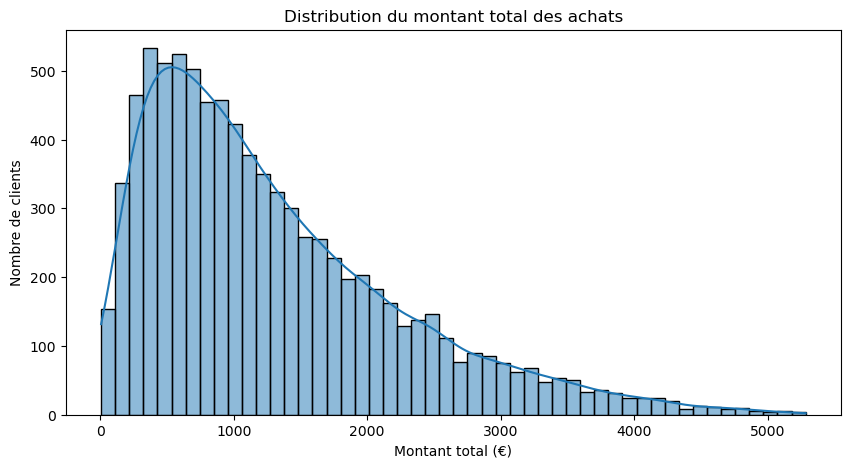

In [117]:
# visualiser le montant total pour voir si cela ressemble à une distribution normale
# pour décider si un test de corrélation paramétrique convient
plt.figure(figsize=(10, 5))

sns.histplot(
    data=clients_stats_b2c,
    x="montant_total",
    bins=50,
    kde=True
)

plt.title("Distribution du montant total des achats")
plt.xlabel("Montant total (€)")
plt.ylabel("Nombre de clients")

plt.show()

la distribution semble s'écarter de la loi normale

In [118]:
# on test l'hypothèse nulle de la distribution normale
# Test de Shapiro-Wilk

from scipy.stats import shapiro

echantillon_age = clients_stats_b2c["age"].sample(
    n=5000,
    random_state=42
)

echantillon_montant = clients_stats_b2c["montant_total"].sample(
    n=5000,
    random_state=42
)

shapiro_age = shapiro(echantillon_age)
shapiro_montant = shapiro(echantillon_montant)

print(
    f"Âge — W = {shapiro_age.statistic:.4f}, "
    f"p-value = {shapiro_age.pvalue:.6e}"
)

print(
    f"Montant total — W = {shapiro_montant.statistic:.4f}, "
    f"p-value = {shapiro_montant.pvalue:.6e}"
)

Âge — W = 0.9700, p-value = 4.112234e-31
Montant total — W = 0.9061, p-value = 3.682989e-48


On rejette la normalité

Il faut utiliser le test non-paramétrique (spearman) plutot que pearson, mais je calcule les deux

In [119]:
from scipy.stats import pearsonr, spearmanr

r_pearson, p_pearson = pearsonr(
    clients_stats_b2c["age"],
    clients_stats_b2c["montant_total"]
)

rho_spearman, p_spearman = spearmanr(
    clients_stats_b2c["age"],
    clients_stats_b2c["montant_total"]
)

print(
    f"Pearson : r = {r_pearson:.4f}, "
    f"p-value = {p_pearson:.6e}"
)

print(
    f"Spearman : rho = {rho_spearman:.4f}, "
    f"p-value = {p_spearman:.6e}"
)

Pearson : r = -0.1876, p-value = 6.663512e-69
Spearman : rho = -0.1845, p-value = 1.021291e-66


la correlation est statistiquement significative mais très faible, de plus, elle ne semble pas linéaire sur le nuage des points. Je vais donc utiliser les tranches d'age

nous avons désormais une variable qualitative catégorielle et une variable quantitative

 <span style="font-size: 16px; font-weight: bold; color :purple; "> avec les tranches d'age </span>

In [120]:
# pour regarder les stats descriptives

resume_montant20 = (
    clients_stats_b2c
    .groupby("tranche_age20", observed=False)["montant_total"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
)

resume_montant20["ecart_interquartile"] = (
    resume_montant20["q3"] - resume_montant20["q1"]
)

resume_montant20.round(2)

,effectif,moyenne,mediane,q1,q3,ecart_interquartile
tranche_age20,,,,,,
17-30 ans,2080,1351.90,1139.40,638.31,1884.27,1245.97
31-50 ans,3410,1556.50,1260.53,700.67,2203.62,1502.95
51-70 ans,2457,993.45,818.22,429.62,1397.34,967.72
71 ans et plus,649,898.04,743.95,394.64,1253.44,858.80


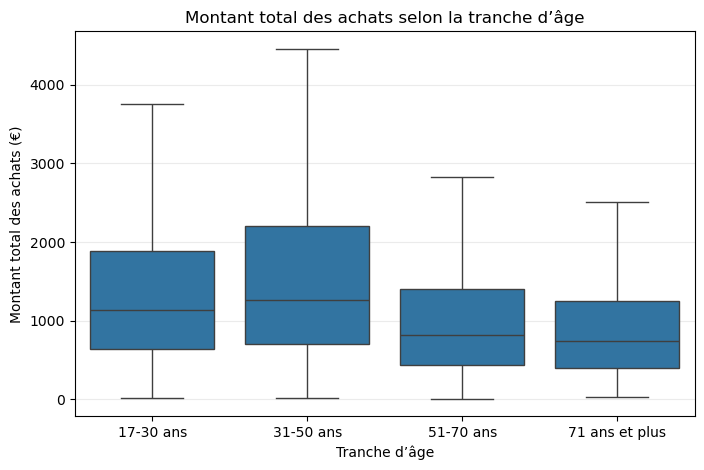

In [121]:
# un plotbox pour comparer les distributions 

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clients_stats_b2c,
    x="tranche_age20",
    y="montant_total",
    showfliers=False
)

plt.title("Montant total des achats selon la tranche d’âge")
plt.xlabel("Tranche d’âge")
plt.ylabel("Montant total des achats (€)")
plt.grid(axis="y", alpha=0.25)

plt.show()

In [122]:
# test de Kruskal-Wallis 


from scipy.stats import kruskal

groupes_montant20 = [
    groupe["montant_total"].values
    for _, groupe in clients_stats_b2c.groupby(
        "tranche_age20",
        observed=False
    )
]

statistique_h, p_value = kruskal(*groupes_montant20)

print(f"Statistique H : {statistique_h:.4f}")
print(f"P-value : {p_value:.6e}")

Statistique H : 556.4475
P-value : 2.782252e-120


In [123]:
# imprimer la décision finale
alpha = 0.05

if p_value < alpha:
    print(
        "Rejet de H0 : le montant total diffère "
        "significativement selon les tranches d’âge."
    )
else:
    print(
        "H0 n’est pas rejetée : aucune différence "
        "significative n’est mise en évidence."
    )

Rejet de H0 : le montant total diffère significativement selon les tranches d’âge.


In [124]:
# calcul de epsilon carré pour voir si l'effet est fort ou faible

n = len(clients_stats_b2c)
k = clients_stats_b2c["tranche_age20"].nunique()

epsilon_carre = (
    statistique_h - k + 1
) / (
    n - k
)

epsilon_carre = max(0, epsilon_carre)

print(f"Epsilon carré : {epsilon_carre:.4f}")

Epsilon carré : 0.0644


l'effet de l'age est modéré

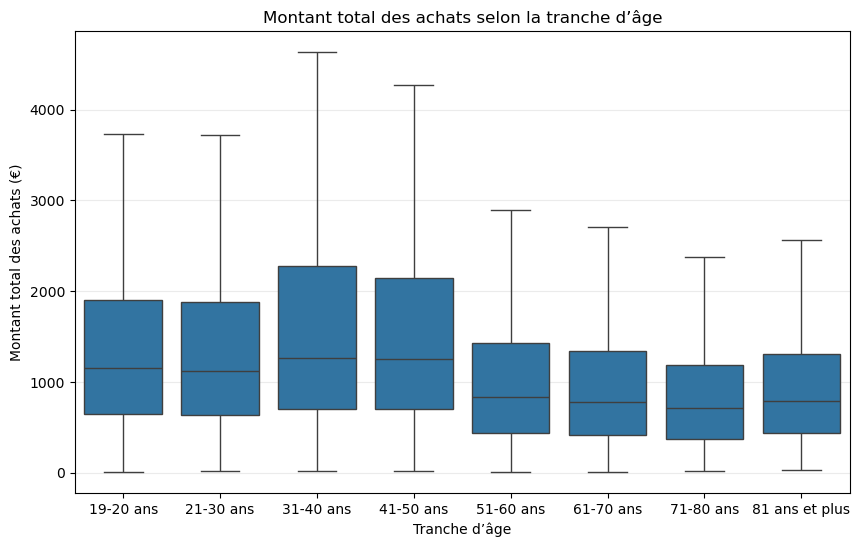

In [125]:
# même chose avec les tranche d'age de 10 ans
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clients_stats_b2c,
    x="tranche_age10",
    y="montant_total",
    showfliers=False
)

plt.title("Montant total des achats selon la tranche d’âge")
plt.xlabel("Tranche d’âge")
plt.ylabel("Montant total des achats (€)")
plt.grid(axis="y", alpha=0.25)

plt.show()

<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        D- lien entre l'age et la fréquence d'achat
    </span>
</div>

In [126]:
resume_frequence20 = (
    clients_stats_b2c
    .groupby("tranche_age20", observed=False)["nombre_achats"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75)
    )
)

resume_frequence20["ecart_interquartile"] = (
    resume_frequence20["q3"] - resume_frequence20["q1"]
)

resume_frequence20.round(2)

,effectif,moyenne,mediane,q1,q3,ecart_interquartile
tranche_age20,,,,,,
17-30 ans,2080,19.12,17.0,10.0,26.0,16.0
31-50 ans,3410,47.41,37.0,20.0,68.0,48.0
51-70 ans,2457,39.50,30.0,16.0,57.0,41.0
71 ans et plus,649,36.91,27.0,15.0,51.0,36.0


### 

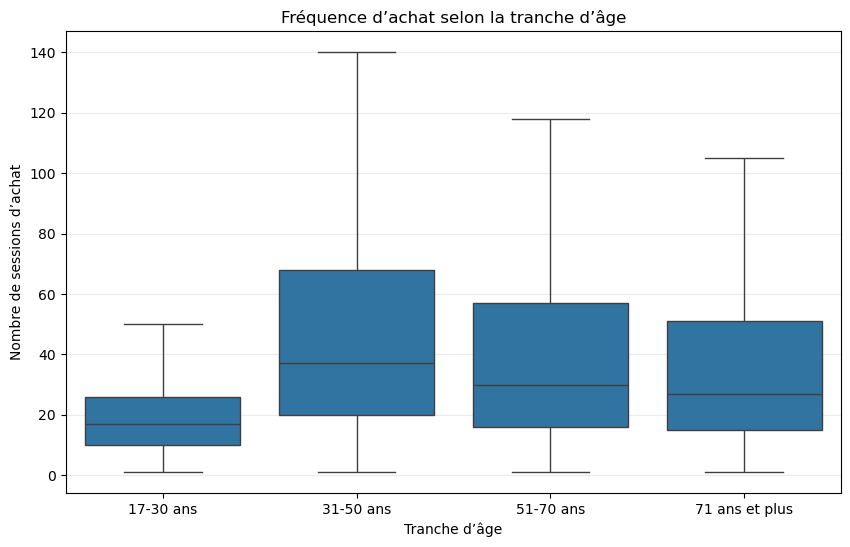

In [127]:
# le graphique à moustache pour les catégories et fréquence d'achat

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clients_stats_b2c,
    x="tranche_age20",
    y="nombre_achats",
    showfliers=False
)

plt.title("Fréquence d’achat selon la tranche d’âge")
plt.xlabel("Tranche d’âge")
plt.ylabel("Nombre de sessions d’achat")
plt.grid(axis="y", alpha=0.25)

plt.show()

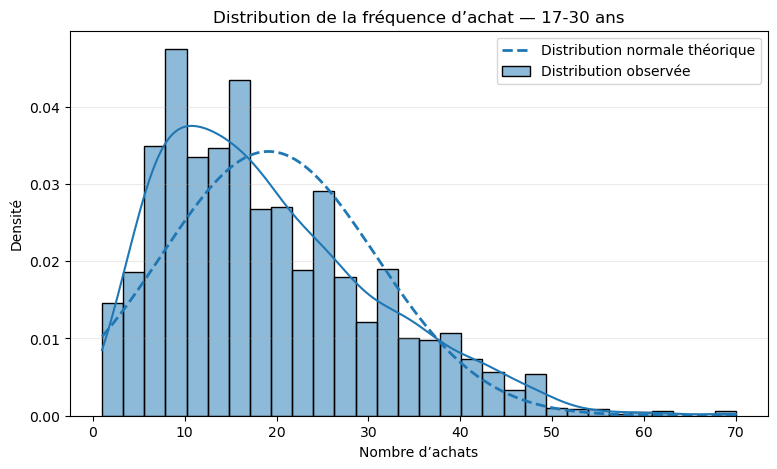

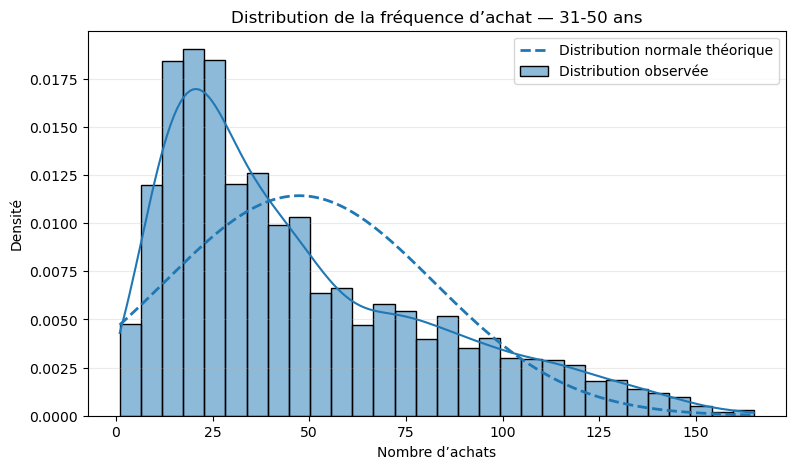

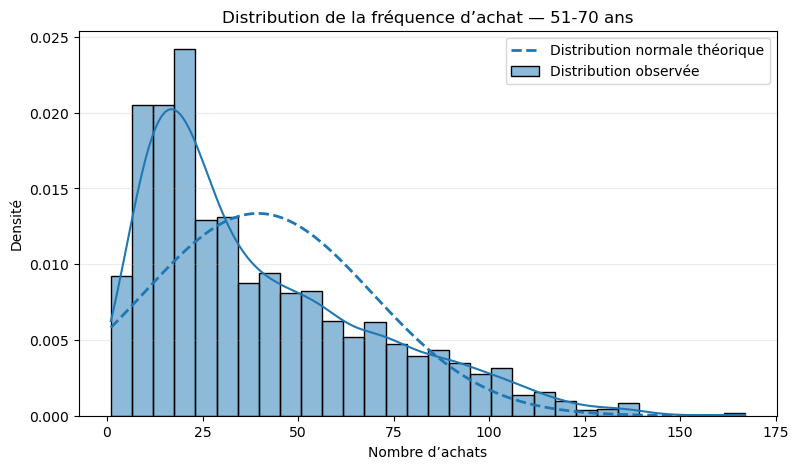

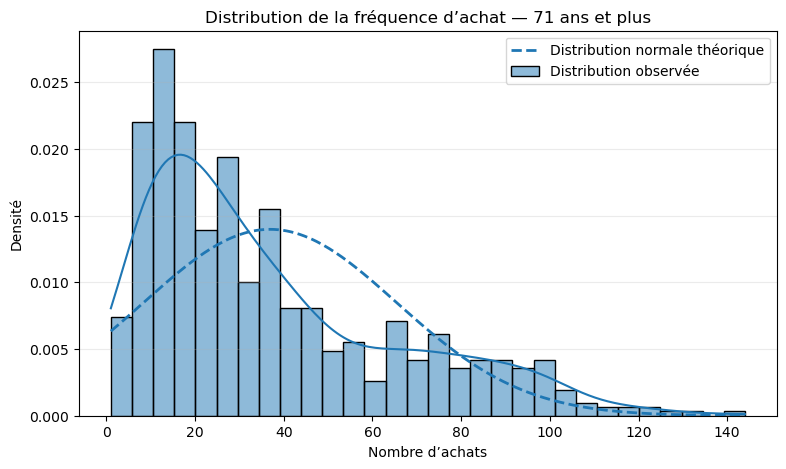

In [128]:
# graph pour voir si les nombre d'achat à l'intérieur de chaque tranche est normalement distribué


from scipy.stats import norm

for tranche in clients_stats_b2c["tranche_age20"].cat.categories:

    valeurs = clients_stats_b2c.loc[
        clients_stats_b2c["tranche_age20"] == tranche,
        "nombre_achats"
    ]

    moyenne = valeurs.mean()
    ecart_type = valeurs.std()

    x = np.linspace(
        valeurs.min(),
        valeurs.max(),
        300
    )

    plt.figure(figsize=(9, 5))

    sns.histplot(
        valeurs,
        bins=30,
        stat="density",
        kde=True,
        label="Distribution observée"
    )

    plt.plot(
        x,
        norm.pdf(x, moyenne, ecart_type),
        linestyle="--",
        linewidth=2,
        label="Distribution normale théorique"
    )

    plt.title(
        f"Distribution de la fréquence d’achat — {tranche}"
    )
    plt.xlabel("Nombre d’achats")
    plt.ylabel("Densité")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)

    plt.show()

si les formes ressemblaient à une distribution normale, on aurait pu faire des test d'égalité des variances, mais ici ce n'est pas le cas visiblement. Donc le test anova ne convient pas. 

In [129]:
# test d'une différence significative entre les groupes

from scipy.stats import kruskal

groupes_frequence20 = [
    groupe["nombre_achats"].values
    for _, groupe in clients_stats_b2c.groupby(
        "tranche_age20",
        observed=True
    )
]

statistique_h, p_value = kruskal(*groupes_frequence20)

print(f"Statistique H : {statistique_h:.4f}")
print(f"P-value : {p_value:.6e}")

Statistique H : 1213.9139
P-value : 7.019920e-263


In [130]:
alpha = 0.05

if p_value < alpha:
    print(
        "Rejet de H0 : la fréquence d’achat diffère "
        "significativement selon les tranches d’âge."
    )
else:
    print(
        "H0 n’est pas rejetée : aucune différence significative "
        "de fréquence d’achat n’est mise en évidence."
    )

Rejet de H0 : la fréquence d’achat diffère significativement selon les tranches d’âge.


In [131]:
# calcul de l'espsilon carré pour voir l'effet de la taille
n = len(clients_stats_b2c)
k = clients_stats_b2c["tranche_age20"].nunique()

epsilon_carre = (
    statistique_h - k + 1
) / (
    n - k
)

epsilon_carre = max(0, epsilon_carre)

print(f"Epsilon carré : {epsilon_carre:.4f}")

Epsilon carré : 0.1409


In [132]:
# comparaison 2 à 2
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

modalites = (
    clients_stats_b2c["tranche_age20"]
    .dropna()
    .unique()
)

resultats_frequence20 = []

for groupe_a, groupe_b in combinations(modalites, 2):

    valeurs_a = clients_stats_b2c.loc[
        clients_stats_b2c["tranche_age20"] == groupe_a,
        "nombre_achats"
    ]

    valeurs_b = clients_stats_b2c.loc[
        clients_stats_b2c["tranche_age20"] == groupe_b,
        "nombre_achats"
    ]

    statistique_u, p_brute = mannwhitneyu(
        valeurs_a,
        valeurs_b,
        alternative="two-sided"
    )

    resultats_frequence20.append({
        "comparaison": f"{groupe_a} vs {groupe_b}",
        "statistique_U": statistique_u,
        "p_value_brute": p_brute
    })

resultats_frequence20 = pd.DataFrame(resultats_frequence20)

resultats_frequence20["p_value_corrigee"] = multipletests(
    resultats_frequence20["p_value_brute"],
    method="holm"
)[1]

resultats_frequence20["significatif"] = (
    resultats_frequence20["p_value_corrigee"] < 0.05
)

resultats_frequence20

,comparaison,statistique_U,p_value_brute,p_value_corrigee,significatif
0,51-70 ans vs 31-50 ans,3634243.0,4.296490e-18,1.288947e-17,True
1,51-70 ans vs 71 ans et plus,838347.5,4.332852e-02,4.332852e-02,True
2,51-70 ans vs 17-30 ans,3638151.5,5.022334e-134,2.511167e-133,True
3,31-50 ans vs 71 ans et plus,1309191.5,1.298490e-13,2.596980e-13,True
4,31-50 ans vs 17-30 ans,5498374.5,2.318052e-257,1.390831e-256,True
5,71 ans et plus vs 17-30 ans,925349.5,2.420803e-46,9.683213e-46,True


<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        E- lien entre l'age et le panier moyen
    </span>
</div>

In [133]:
# tableau descriptif
resume_panier20 = (
    clients_stats_b2c
    .groupby("tranche_age20", observed=False)["panier_moyen"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        ecart_type="std"
    )
)

resume_panier20["ecart_interquartile"] = (
    resume_panier20["q3"] - resume_panier20["q1"]
)

resume_panier20.round(2)

,effectif,moyenne,mediane,q1,q3,ecart_type,ecart_interquartile
tranche_age20,,,,,,,
17-30 ans,2080,69.68,67.02,54.02,82.36,24.30,28.34
31-50 ans,3410,34.88,32.17,28.79,37.04,11.59,8.25
51-70 ans,2457,26.96,24.57,20.81,30.42,10.23,9.61
71 ans et plus,649,26.49,24.08,20.94,29.87,9.16,8.93


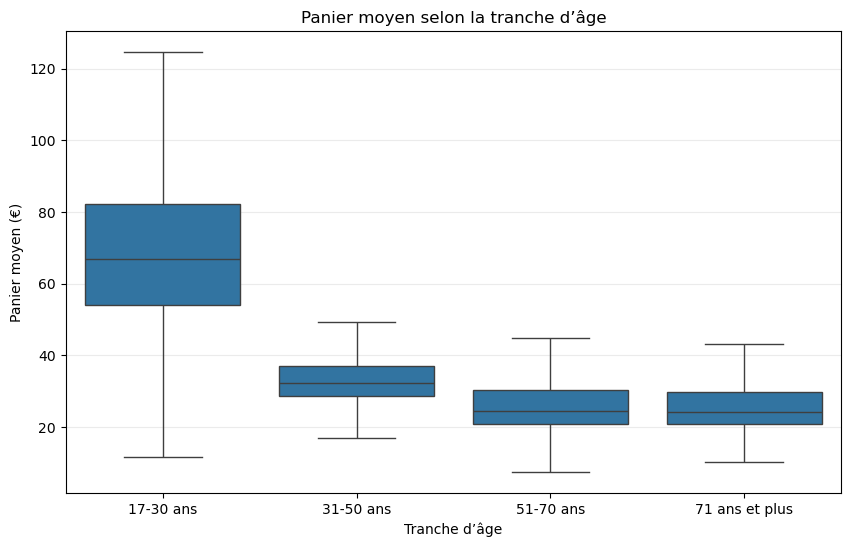

In [134]:
# boite à moustache age et panier moyen

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=clients_stats_b2c,
    x="tranche_age20",
    y="panier_moyen",
    showfliers=False
)

plt.title("Panier moyen selon la tranche d’âge")
plt.xlabel("Tranche d’âge")
plt.ylabel("Panier moyen (€)")
plt.grid(axis="y", alpha=0.25)

plt.show()

voyons si le panier moyen est normalement distribué à l'intérieur de chaque tranche 

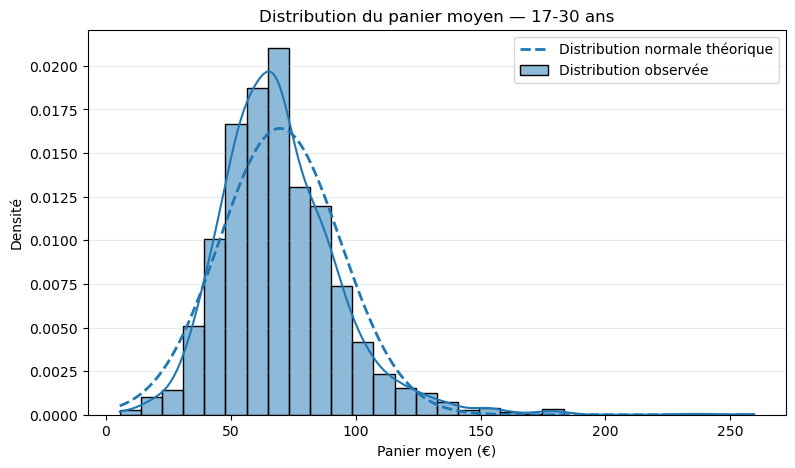

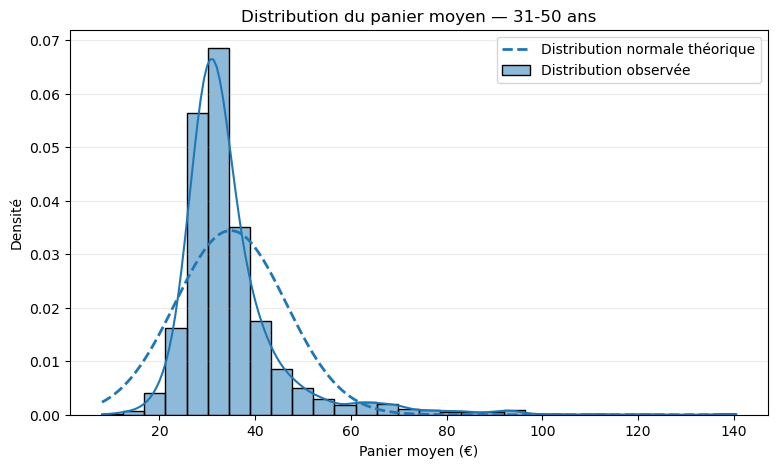

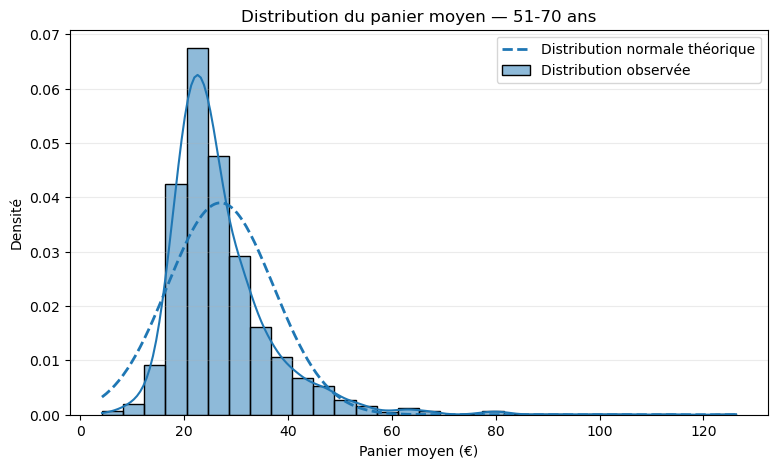

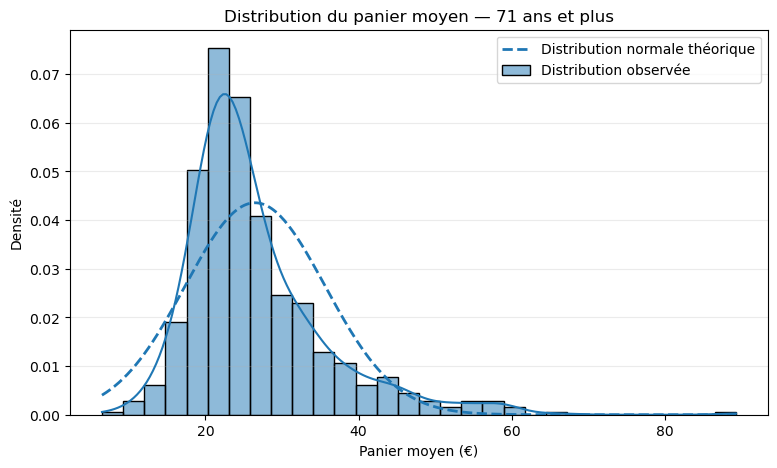

In [135]:
# voyons si le panier moyen est normalement distribué à l'intérieur de chaque tranche 
# les graphiques de densité

from scipy.stats import norm

for tranche, groupe in clients_stats_b2c.groupby(
    "tranche_age20",
    observed=True
):

    valeurs = groupe["panier_moyen"]

    moyenne = valeurs.mean()
    ecart_type = valeurs.std()

    x = np.linspace(
        valeurs.min(),
        valeurs.max(),
        300
    )

    plt.figure(figsize=(9, 5))

    sns.histplot(
        valeurs,
        bins=30,
        stat="density",
        kde=True,
        label="Distribution observée"
    )

    plt.plot(
        x,
        norm.pdf(x, moyenne, ecart_type),
        linestyle="--",
        linewidth=2,
        label="Distribution normale théorique"
    )

    plt.title(f"Distribution du panier moyen — {tranche}")
    plt.xlabel("Panier moyen (€)")
    plt.ylabel("Densité")
    plt.legend()
    plt.grid(axis="y", alpha=0.25)

    plt.show()

les distributions ne sont pas facile à juger visuellement, faisons le test de shapiro-wilk

In [136]:
# tests de normalité shapiro-wwilk par tranche

from scipy.stats import shapiro

for tranche, groupe in clients_stats_b2c.groupby(
    "tranche_age20",
    observed=True
):

    valeurs = groupe["panier_moyen"]

    # Shapiro est limité à 5 000 valeurs pour une p-value fiable
    if len(valeurs) > 5000:
        valeurs = valeurs.sample(
            n=5000,
            random_state=42
        )

    statistique, p_value = shapiro(valeurs)

    print(
        f"{tranche} : W = {statistique:.4f}, "
        f"p-value = {p_value:.6e}"
    )

17-30 ans : W = 0.9330, p-value = 1.375565e-29
31-50 ans : W = 0.7409, p-value = 1.327581e-58
51-70 ans : W = 0.8195, p-value = 2.933070e-46
71 ans et plus : W = 0.8632, p-value = 2.453738e-23


In [137]:
# test de l'égalité de la variance entre les tranches

from scipy.stats import levene

groupes_panier20 = [
    groupe["panier_moyen"].values
    for _, groupe in clients_stats_b2c.groupby(
        "tranche_age20",
        observed=True
    )
]

stat_levene, p_levene = levene(
    *groupes_panier20,
    center="median"
)

print(f"Levene : statistique = {stat_levene:.4f}")
print(f"P-value = {p_levene:.6e}")

Levene : statistique = 491.4808
P-value = 9.243455e-295


les distributions ne sont pas normales et au moins une variance est différente, donc on ne peut pas utiliser ANOVA

In [138]:
# test de Kruskal-Wallis
from scipy.stats import kruskal

statistique_h, p_value = kruskal(*groupes_panier20)

print(f"Kruskal-Wallis : H = {statistique_h:.4f}")
print(f"P-value = {p_value:.6e}")

Kruskal-Wallis : H = 4714.3139
P-value = 0.000000e+00


In [139]:
# test de taille de l'effet. epsilon carré
n = len(clients_stats_b2c)
k = clients_stats_b2c["tranche_age20"].nunique()

epsilon_carre = (
    statistique_h - k + 1
) / (
    n - k
)

epsilon_carre = max(0, epsilon_carre)

print(f"Epsilon carré : {epsilon_carre:.4f}")

Epsilon carré : 0.5483


la taille de l'effet est très importante

In [140]:
# comparaison 2 par 2 de différence entre les tranches

from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd

# Conserver l’ordre défini pour les tranches d’âge
modalites = [
    tranche
    for tranche in clients_stats_b2c["tranche_age20"].cat.categories
    if (clients_stats_b2c["tranche_age20"] == tranche).any()
]

resultats_panier20 = []

for groupe_a, groupe_b in combinations(modalites, 2):

    valeurs_a = clients_stats_b2c.loc[
        clients_stats_b2c["tranche_age20"] == groupe_a,
        "panier_moyen"
    ]

    valeurs_b = clients_stats_b2c.loc[
        clients_stats_b2c["tranche_age20"] == groupe_b,
        "panier_moyen"
    ]

    statistique_u, p_brute = mannwhitneyu(
        valeurs_a,
        valeurs_b,
        alternative="two-sided",
        method="asymptotic"
    )

    # Taille d’effet : corrélation bisérielle de rang
    effet_r = (
        2 * statistique_u / (len(valeurs_a) * len(valeurs_b))
        - 1
    )

    resultats_panier20.append({
        "comparaison": f"{groupe_a} vs {groupe_b}",
        "mediane_groupe_1": valeurs_a.median(),
        "mediane_groupe_2": valeurs_b.median(),
        "difference_medianes": valeurs_a.median() - valeurs_b.median(),
        "statistique_U": statistique_u,
        "p_value_brute": p_brute,
        "effet_r": effet_r
    })

resultats_panier20 = pd.DataFrame(resultats_panier20)

# Correction pour les comparaisons multiples
resultats_panier20["p_value_corrigee"] = multipletests(
    resultats_panier20["p_value_brute"],
    method="holm"
)[1]

resultats_panier20["significatif"] = (
    resultats_panier20["p_value_corrigee"] < 0.05
)

resultats_panier20[
    [
        "comparaison",
        "mediane_groupe_1",
        "mediane_groupe_2",
        "difference_medianes",
        "p_value_corrigee",
        "effet_r",
        "significatif"
    ]
].round(4)

,comparaison,mediane_groupe_1,mediane_groupe_2,difference_medianes,p_value_corrigee,effet_r,significatif
0,17-30 ans vs 31-50 ans,67.015,32.175,34.840,0.0000,0.8636,True
1,17-30 ans vs 51-70 ans,67.015,24.570,42.445,0.0000,0.9336,True
2,17-30 ans vs 71 ans et plus,67.015,24.080,42.935,0.0000,0.9411,True
3,31-50 ans vs 51-70 ans,32.175,24.570,7.605,0.0000,0.5387,True
4,31-50 ans vs 71 ans et plus,32.175,24.080,8.095,0.0000,0.5669,True
5,51-70 ans vs 71 ans et plus,24.570,24.080,0.490,0.3807,0.0223,False


<div style="border-left: 5px solid rgb(150,100,182); padding: 10px; background-color: #f5fafa;">
    <span style="font-size: 22px; color: rgb(150,100,182); font-weight: bold;">
        D- lien entre l'age et la catégorie de livre
    </span>
</div>

In [141]:
# tableau de contingeance
table_age_categorie = pd.crosstab(
    ventes_b2c["tranche_age20"],
    ventes_b2c["categ"]
)

table_age_categorie.columns = [
    "Catégorie 0",
    "Catégorie 1",
    "Catégorie 2"
]

table_age_categorie

,Catégorie 0,Catégorie 1,Catégorie 2
tranche_age20,,,
17-30 ans,15446,27630,27531
31-50 ans,288613,94852,3759
51-70 ans,68448,78440,1257
71 ans et plus,14774,19683,301


In [142]:
# table des contingence en proportion
pourcent_age_categorie = (
    table_age_categorie
    .div(table_age_categorie.sum(axis=1), axis=0)
    * 100
)

pourcent_age_categorie.round(2)

,Catégorie 0,Catégorie 1,Catégorie 2
tranche_age20,,,
17-30 ans,21.88,39.13,38.99
31-50 ans,74.53,24.50,0.97
51-70 ans,46.20,52.95,0.85
71 ans et plus,42.51,56.63,0.87


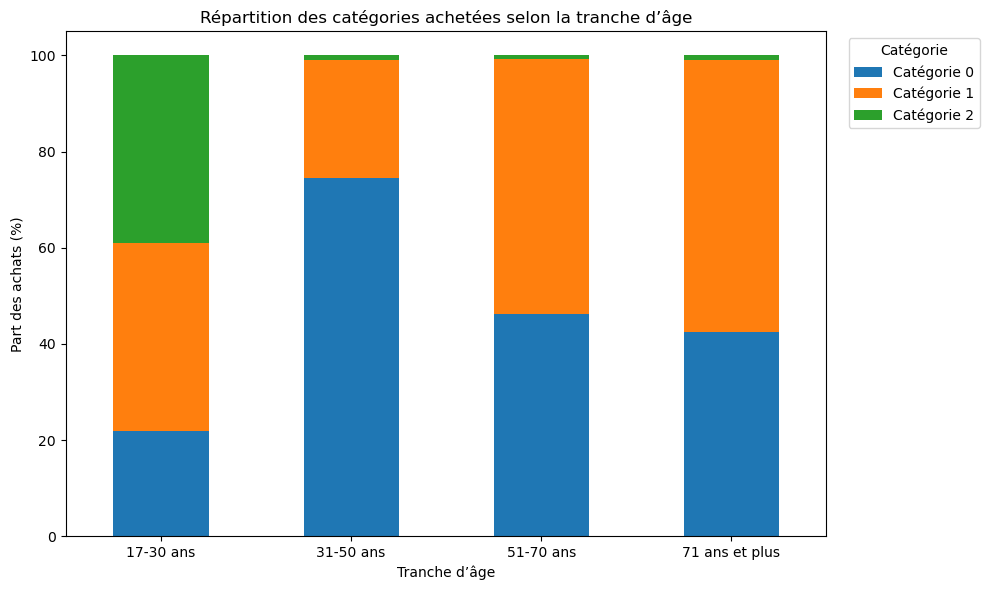

In [143]:
# Graphique en barres empilées
ax = pourcent_age_categorie.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Répartition des catégories achetées selon la tranche d’âge")
plt.xlabel("Tranche d’âge")
plt.ylabel("Part des achats (%)")
plt.xticks(rotation=0)
plt.legend(
    title="Catégorie",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [144]:
# Test du khi²
from scipy.stats import chi2_contingency

chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(
    table_age_categorie
)

print(f"Statistique du khi² : {chi2:.4f}")
print(f"Degrés de liberté : {ddl}")
print(f"P-value : {p_value:.6e}")

Statistique du khi² : 245715.8178
Degrés de liberté : 6
P-value : 0.000000e+00


In [145]:
table_effectifs_theoriques = pd.DataFrame(
    effectifs_theoriques,
    index=table_age_categorie.index,
    columns=table_age_categorie.columns
)

print(
    "Effectif théorique minimum :",
    table_effectifs_theoriques.min().min()
)

print(
    "Nombre de cellules inférieures à 5 :",
    (table_effectifs_theoriques < 5).sum().sum()
)

Effectif théorique minimum : 1781.9107211416906
Nombre de cellules inférieures à 5 : 0


In [146]:
# test de V de Cramer
import numpy as np

n = table_age_categorie.to_numpy().sum()
nombre_lignes, nombre_colonnes = table_age_categorie.shape

v_cramer = np.sqrt(
    (chi2 / n)
    / min(
        nombre_lignes - 1,
        nombre_colonnes - 1
    )
)

print(f"V de Cramér : {v_cramer:.4f}")

V de Cramér : 0.4379


In [147]:
# les résidus standardisés pour expliquer cette association
residus_age_categorie = (
    table_age_categorie - effectifs_theoriques
) / np.sqrt(effectifs_theoriques)

residus_age_categorie = pd.DataFrame(
    residus_age_categorie,
    index=table_age_categorie.index,
    columns=table_age_categorie.columns
)

residus_age_categorie.round(2)

,Catégorie 0,Catégorie 1,Catégorie 2
tranche_age20,,,
17-30 ans,-131.82,21.29,397.43
31-50 ans,112.78,-105.36,-114.22
51-70 ans,-70.50,121.47,-72.72
71 ans et plus,-43.02,70.53,-35.08


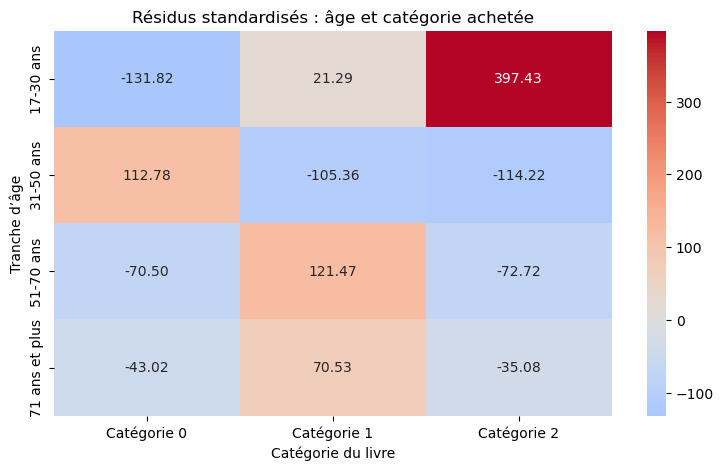

In [148]:
# heatmap
plt.figure(figsize=(9, 5))

sns.heatmap(
    residus_age_categorie,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Résidus standardisés : âge et catégorie achetée")
plt.xlabel("Catégorie du livre")
plt.ylabel("Tranche d’âge")
#plt.savefig("heatmap_age_category.png", dpi=300, bbox_inches="tight")
plt.show()